**Main imports**

In [1]:
# !pip install numpy
# !pip install torch
# !pip install torchvision
# !pip install matplotlib

In [2]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython import display as disp
from torch.nn.utils import spectral_norm

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

**Import dataset**

In [3]:
# helper function to make getting another batch of data easier
def cycle(iterable):
    while True:
        for x in iterable:
            yield x

class_names = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle','bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle','chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur','dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','computer_keyboard','lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain','mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree','plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket','rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider','squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor','train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm',]

train_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=True, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

test_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=False, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

train_iterator = iter(cycle(train_loader))
test_iterator = iter(cycle(test_loader))

print(f'> Size of training dataset {len(train_loader.dataset)}')
print(f'> Size of test dataset {len(test_loader.dataset)}')

/home3/hqcb32/deeplearningcourseworkenv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


> Size of training dataset 50000
> Size of test dataset 10000


**View some of the test dataset**

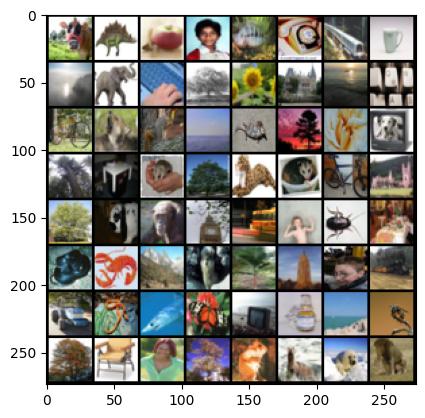

In [4]:
# let's view some of the training data
plt.rcParams['figure.dpi'] = 100
x,t = next(train_iterator)
x,t = x.to(device), t.to(device)
plt.imshow(torchvision.utils.make_grid(x).cpu().numpy().transpose(1, 2, 0), cmap=plt.cm.binary)
plt.show()

In [5]:
# ResNet blocks
# separating things so the actual model code looks more digestiable also for ResGan

class ResBlockUp(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)

        self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.relu(self.bn1(x), inplace=True)
        h = F.interpolate(h, scale_factor=2, mode="nearest")
        h = self.conv1(h)

        h = F.relu(self.bn2(h), inplace=True)
        h = self.conv2(h)

        s = F.interpolate(x, scale_factor=2, mode="nearest")
        s = self.skip(s)
        return h + s
    
class ResBlockDown(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.relu(x, inplace=True)
        h = self.conv1(h)
        h = F.relu(h, inplace=True)
        h = self.conv2(h)
        h = F.avg_pool2d(h, kernel_size=2)

        s = F.avg_pool2d(x, kernel_size=2)
        s = self.skip(s)
        return h + s

In [6]:
def minibatch_stddev(h: torch.Tensor) -> torch.Tensor:
    # scalar measuring variation across the batch
    std = h.std(dim=0, unbiased=False).mean()  # one scalar
    std_map = std.expand(h.size(0), 1, h.size(2), h.size(3))
    return torch.cat([h, std_map], dim=1)

In [7]:
class ResBlock(nn.Module):
    def __init__(self, ch: int):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(ch)
        self.bn2 = nn.BatchNorm2d(ch)
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        h = F.relu(self.bn1(x), inplace=True)
        h = self.conv1(h)
        h = F.relu(self.bn2(h), inplace=True)
        h = self.conv2(h)
        return x + h

In [8]:
# -------------------------
# Generator
# -------------------------

class Generator(nn.Module):
    """
    CIFAR-sized generator:
      z (B, z_dim) -> (B, 3, 32, 32)
    """
    def __init__(self, z_dim: int = 128, base_channels: int = 90):
        super().__init__()
        ch = base_channels

        # project z -> 4x4 feature map
        self.fc = nn.Linear(z_dim, ch * 4 * 4)

        # 4->8->16->32
        self.rb1 = ResBlockUp(ch, ch)          # 4 -> 8
        self.rb2 = ResBlockUp(ch, ch)          # 8 -> 16
        self.rb3 = ResBlockUp(ch, ch // 2)     # 16 -> 32
        self.rb4 = ResBlock(ch // 2) #4th layer
        # NEW: same-resolution block at 32x32
        self.bn = nn.BatchNorm2d(ch // 2)
        self.conv_out = nn.Conv2d(ch // 2, 3, kernel_size=3, padding=1)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        h = self.fc(z).view(z.size(0), -1, 4, 4)
        h = self.rb1(h)
        h = self.rb2(h)
        h = self.rb3(h)
        h = self.rb4(h) #Adding a 4th layer just to see if we can get better defined shapes
        h = F.relu(self.bn(h), inplace=True)
        x = torch.tanh(self.conv_out(h))
        return x

In [9]:
# Discriminator


class Discriminator(nn.Module):
    """
    CIFAR-sized discriminator:
      x (B, 3, 32, 32) -> logits (B, 1)
    """
    def __init__(self, base_channels: int = 90):
        super().__init__()
        ch = base_channels

        self.conv_in = nn.Conv2d(3, ch // 2, kernel_size=3, padding=1)

        # 32->16->8->4
        self.rb1 = ResBlockDown(ch // 2, ch)   # 32 -> 16
        self.rb2 = ResBlockDown(ch, ch)        # 16 -> 8
        self.rb3 = ResBlockDown(ch, ch)        # 8 -> 4

        self.fc = nn.Linear(ch * 4 * 4, 1)
#         self.fc = nn.Linear((ch + 1) * 4 * 4, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.conv_in(x)
        h = self.rb1(h)
        h = self.rb2(h)
        h = self.rb3(h)
        h = F.relu(h, inplace=True)
        
        # ---- minibatch stddev channel (adds 1 channel) ----
#         h = minibatch_stddev(h)   # (B, ch+1, 4, 4)
        
        h = h.view(h.size(0), -1)
        return self.fc(h)

In [10]:
def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

G = Generator(z_dim=128, base_channels=88).to(device) # DID WELL AT 80 FOR BOTH
D = Discriminator(base_channels=88).to(device)

print("G params:", count_params(G))
print("D params:", count_params(D))
print("Total  :", count_params(G) + count_params(D))

if (len(torch.nn.utils.parameters_to_vector(G.parameters())) + len(torch.nn.utils.parameters_to_vector(D.parameters()))) > 1000000:
    print("> Warning: you have gone over your parameter budget and will have a grade penalty!")

G params: 570067
D params: 406121
Total  : 976188


In [11]:
# USING EMA SO WE CAN KEEP CHOOSING THE RIGHT VERSION

import copy

@torch.no_grad()
def ema_update(ema_model, model, decay: float):
    # ema = decay*ema + (1-decay)*model
    ema_params = dict(ema_model.named_parameters())
    model_params = dict(model.named_parameters())
    for name, p in model_params.items():
        ema_params[name].mul_(decay).add_(p, alpha=1.0 - decay)

    for ema_buf, buf in zip(ema_model.buffers(), model.buffers()):
        ema_buf.copy_(buf)

G_ema = copy.deepcopy(G).to(device)
G_ema.eval()  # EMA model is only used for sampling/eval
for p in G_ema.parameters():
    p.requires_grad_(False)
    
ema_decay = 0.999

In [12]:
# initialise the optimiser
opt_G = torch.optim.Adam(G.parameters(), lr=0.0003, betas=(0.0, 0.9))
opt_D = torch.optim.Adam(D.parameters(), lr=0.0004, betas=(0.0, 0.9))

steps = 0

In [13]:
def get_aug_params(step):
    if step < 20_000: # was 10k
        return 0.8, 1     # easier early, still regularised, was 0.8
    elif step < 80_000: # was 40k
        return 1.0, 2     # full DiffAug mid-training, was 8???
    else:
        return 0.3, 1     # late: allow sharpening, was 0.3
    
# 0.5, 8, 0.3 gave FID = 49

In [14]:
from collections import defaultdict
import time
import math

# trackers for plotting aka for data analysis
metrics = defaultdict(list)
t0 = time.time()

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += p.grad.detach().pow(2).sum().item()
    return math.sqrt(total)

def tensor_stats(v):
    # v can be (B,1) or (B,)
    v = v.detach()
    return v.mean().item(), v.std(unbiased=False).item(), v.min().item(), v.max().item()

z_vis_fixed = torch.randn(64, 128, device=device)

In [15]:
# DiffAugment (PyTorch)
import random

def _rand_brightness(x):
    # x: (B,C,H,W) in [-1,1]
    # add per-image scalar in [-0.2, 0.2]
    b = (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5) * 0.4
    return x + b

def _rand_contrast(x):
    # scale deviations from mean by factor in [0.5, 1.5]
    mean = x.mean(dim=(2, 3), keepdim=True)
    factor = torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5
    return (x - mean) * factor + mean

def _rand_saturation(x):
    # interpolate between grayscale and original by factor in [0, 2]
    gray = x.mean(dim=1, keepdim=True)
    factor = torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2.0
    return (x - gray) * factor + gray

def _rand_translation(x, ratio=0.125):
    # translate by up to ratio*H/W pixels using padding + crop (differentiable)
    B, C, H, W = x.shape
    shift_x = int(H * ratio + 0.5)
    shift_y = int(W * ratio + 0.5)
    if shift_x == 0 and shift_y == 0:
        return x

    # pad then random crop
    x_pad = F.pad(x, (shift_y, shift_y, shift_x, shift_x), mode="reflect")
    ox = torch.randint(0, 2 * shift_x + 1, (B,), device=x.device)
    oy = torch.randint(0, 2 * shift_y + 1, (B,), device=x.device)

    out = torch.empty((B, C, H, W), device=x.device, dtype=x.dtype)
    for i in range(B):
        out[i] = x_pad[i, :, ox[i]:ox[i] + H, oy[i]:oy[i] + W]
    return out

def _rand_cutout(x, ratio=0.5):
    # cutout square mask of side ratio*H (filled with 0, i.e. mid-gray in [-1,1] space)
    B, C, H, W = x.shape
    cut_h = int(H * ratio + 0.5)
    cut_w = int(W * ratio + 0.5)
    if cut_h < 1 or cut_w < 1:
        return x

    cx = torch.randint(0, H, (B,), device=x.device)
    cy = torch.randint(0, W, (B,), device=x.device)

    x1 = (cx - cut_h // 2).clamp(0, H)
    x2 = (cx + cut_h // 2).clamp(0, H)
    y1 = (cy - cut_w // 2).clamp(0, W)
    y2 = (cy + cut_w // 2).clamp(0, W)

    out = x.clone()
    for i in range(B):
        out[i, :, x1[i]:x2[i], y1[i]:y2[i]] = 0.0
    return out


def diff_augment(x, p=1.0, translate=2):
    """
    Per-image DiffAugment for CIFAR (32x32).
    """
    if p <= 0:
        return x

    B, C, H, W = x.shape
    device = x.device

    # decide per-image whether to apply augmentation
    apply = (torch.rand(B, device=device) < p).float().view(B, 1, 1, 1)

    out = x

    # random horizontal flip per image
    flip = (torch.rand(B, device=device) < 0.5)
    out = torch.where(
        flip.view(B, 1, 1, 1),
        torch.flip(out, dims=[3]),
        out
    )

    # random translation per image
    if translate > 0:
        dx = torch.randint(-translate, translate + 1, (B,), device=device)
        dy = torch.randint(-translate, translate + 1, (B,), device=device)

        tx = dx.float() * 2.0 / (W - 1)
        ty = dy.float() * 2.0 / (H - 1)

        theta = torch.zeros(B, 2, 3, device=device)
        theta[:, 0, 0] = 1.0
        theta[:, 1, 1] = 1.0
        theta[:, 0, 2] = tx
        theta[:, 1, 2] = ty

        grid = F.affine_grid(theta, out.size(), align_corners=False)
        out = F.grid_sample(
            out, grid,
            mode="bilinear",
            padding_mode="reflection",
            align_corners=False
        )

    # mix augmented and original per-image
    out = apply * out + (1.0 - apply) * x
    return out

# DA_POLICY = "color,translation"

**Main training loop**

x range: -1.0 1.0
opt_steps   500 |  loss_D 2.000 |  loss_G 0.032| D(real) +0.08±0.06 |  D(fake) +0.06±0.06 |  margins real>0.00 fake<0.00 |  ||g|| D 0.4 G 1.1 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  0.4 min
opt_steps  1000 |  loss_D 2.001 |  loss_G 0.019| D(real) -0.10±0.07 |  D(fake) -0.10±0.06 |  margins real>0.00 fake<0.00 |  ||g|| D 0.4 G 0.7 |  G(x) mean -0.05 std 0.57 range[-1.00,+1.00] |  0.8 min
opt_steps  1500 |  loss_D 2.001 |  loss_G 0.046| D(real) -0.29±0.07 |  D(fake) -0.28±0.07 |  margins real>0.00 fake<0.00 |  ||g|| D 0.7 G 0.9 |  G(x) mean -0.09 std 0.55 range[-1.00,+1.00] |  1.2 min
opt_steps  2000 |  loss_D 2.001 |  loss_G 0.114| D(real) -0.15±0.19 |  D(fake) -0.16±0.20 |  margins real>0.00 fake<0.00 |  ||g|| D 1.2 G 3.0 |  G(x) mean -0.07 std 0.53 range[-0.99,+1.00] |  1.7 min


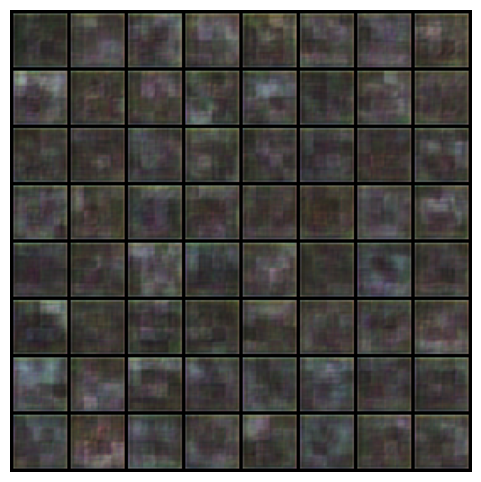

opt_steps  2500 |  loss_D 2.000 |  loss_G 0.179| D(real) +0.60±0.35 |  D(fake) +0.45±0.30 |  margins real>0.06 fake<0.00 |  ||g|| D 3.8 G 6.6 |  G(x) mean -0.03 std 0.56 range[-1.00,+1.00] |  2.1 min
opt_steps  3000 |  loss_D 1.999 |  loss_G 0.199| D(real) -0.09±0.14 |  D(fake) -0.15±0.14 |  margins real>0.00 fake<0.00 |  ||g|| D 1.6 G 1.9 |  G(x) mean -0.06 std 0.52 range[-1.00,+1.00] |  2.5 min
opt_steps  3500 |  loss_D 2.000 |  loss_G 0.171| D(real) +0.28±0.17 |  D(fake) +0.23±0.17 |  margins real>0.00 fake<0.00 |  ||g|| D 1.8 G 2.5 |  G(x) mean -0.03 std 0.52 range[-1.00,+1.00] |  2.9 min
opt_steps  4000 |  loss_D 2.002 |  loss_G 0.129| D(real) +0.05±0.24 |  D(fake) +0.08±0.24 |  margins real>0.00 fake<0.00 |  ||g|| D 2.5 G 2.5 |  G(x) mean -0.06 std 0.55 range[-0.99,+1.00] |  3.3 min


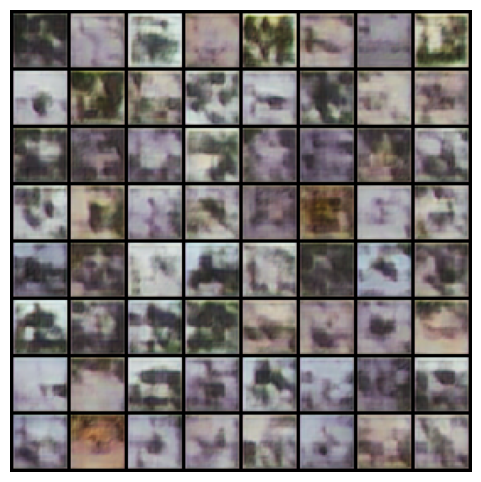

opt_steps  4500 |  loss_D 1.995 |  loss_G 0.138| D(real) -0.54±0.24 |  D(fake) -0.56±0.20 |  margins real>0.00 fake<0.02 |  ||g|| D 2.8 G 2.6 |  G(x) mean -0.05 std 0.51 range[-1.00,+1.00] |  3.7 min
opt_steps  5000 |  loss_D 1.977 |  loss_G 0.203| D(real) +0.18±0.20 |  D(fake) +0.18±0.18 |  margins real>0.00 fake<0.00 |  ||g|| D 2.6 G 2.5 |  G(x) mean -0.02 std 0.55 range[-1.00,+1.00] |  4.1 min
opt_steps  5500 |  loss_D 1.963 |  loss_G 0.242| D(real) -0.27±0.24 |  D(fake) -0.38±0.21 |  margins real>0.00 fake<0.02 |  ||g|| D 2.4 G 2.9 |  G(x) mean -0.02 std 0.54 range[-1.00,+1.00] |  4.5 min
opt_steps  6000 |  loss_D 1.938 |  loss_G 0.269| D(real) +0.03±0.72 |  D(fake) -0.15±0.39 |  margins real>0.08 fake<0.03 |  ||g|| D 4.5 G 5.7 |  G(x) mean -0.04 std 0.54 range[-1.00,+1.00] |  5.0 min


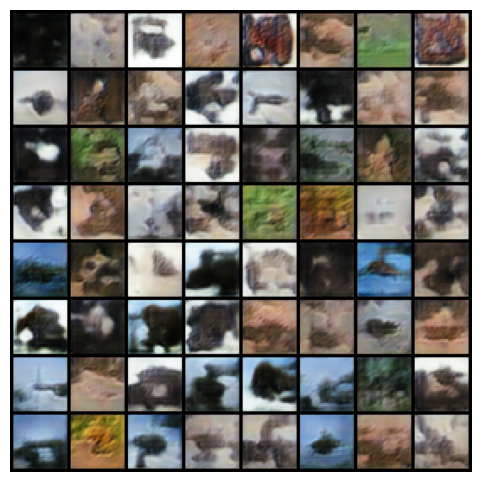

opt_steps  6500 |  loss_D 1.900 |  loss_G 0.301| D(real) +0.94±0.60 |  D(fake) +0.67±0.52 |  margins real>0.38 fake<0.00 |  ||g|| D 11.4 G 5.0 |  G(x) mean -0.04 std 0.53 range[-1.00,+1.00] |  5.4 min
opt_steps  7000 |  loss_D 1.875 |  loss_G 0.330| D(real) +0.19±0.60 |  D(fake) -0.04±0.44 |  margins real>0.09 fake<0.02 |  ||g|| D 4.8 G 4.6 |  G(x) mean -0.05 std 0.56 range[-1.00,+1.00] |  5.8 min
opt_steps  7500 |  loss_D 1.843 |  loss_G 0.338| D(real) -0.07±0.58 |  D(fake) -0.45±0.60 |  margins real>0.05 fake<0.12 |  ||g|| D 6.8 G 10.2 |  G(x) mean -0.02 std 0.52 range[-1.00,+1.00] |  6.2 min
opt_steps  8000 |  loss_D 1.819 |  loss_G 0.360| D(real) -0.45±0.44 |  D(fake) -0.67±0.55 |  margins real>0.00 fake<0.33 |  ||g|| D 10.3 G 5.9 |  G(x) mean +0.00 std 0.54 range[-1.00,+1.00] |  6.6 min


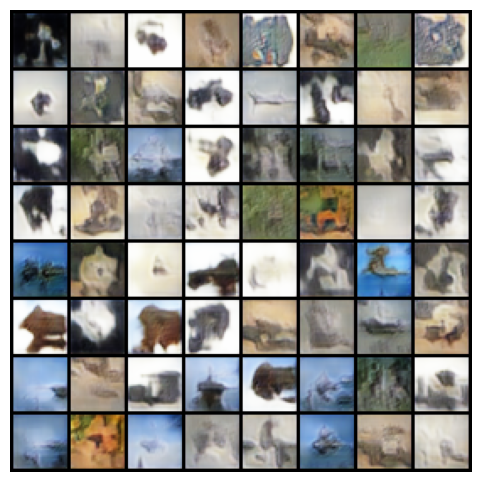

opt_steps  8500 |  loss_D 1.834 |  loss_G 0.374| D(real) +0.17±0.60 |  D(fake) -0.11±0.58 |  margins real>0.12 fake<0.03 |  ||g|| D 5.5 G 6.6 |  G(x) mean -0.04 std 0.53 range[-1.00,+1.00] |  7.0 min
opt_steps  9000 |  loss_D 1.833 |  loss_G 0.368| D(real) +1.64±0.97 |  D(fake) +1.15±0.64 |  margins real>0.70 fake<0.00 |  ||g|| D 24.0 G 4.3 |  G(x) mean -0.02 std 0.52 range[-1.00,+1.00] |  7.4 min
opt_steps  9500 |  loss_D 1.806 |  loss_G 0.377| D(real) -0.18±0.52 |  D(fake) -0.53±0.45 |  margins real>0.02 fake<0.16 |  ||g|| D 7.7 G 9.0 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  7.8 min
opt_steps 10000 |  loss_D 1.762 |  loss_G 0.396| D(real) +1.07±1.34 |  D(fake) +0.31±0.64 |  margins real>0.44 fake<0.00 |  ||g|| D 18.9 G 6.3 |  G(x) mean -0.04 std 0.52 range[-1.00,+1.00] |  8.2 min


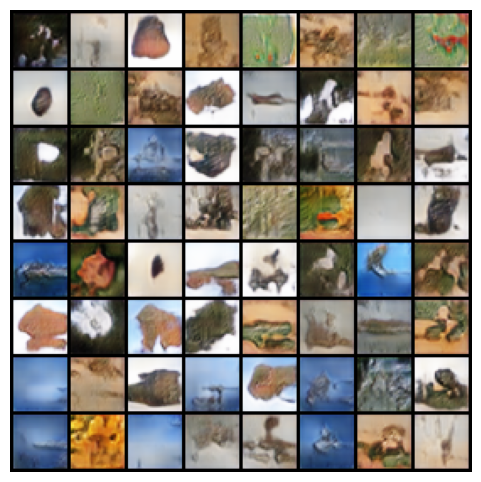

opt_steps 10500 |  loss_D 1.734 |  loss_G 0.428| D(real) +0.30±0.84 |  D(fake) -0.20±0.64 |  margins real>0.16 fake<0.09 |  ||g|| D 9.3 G 6.3 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  8.6 min
opt_steps 11000 |  loss_D 1.723 |  loss_G 0.454| D(real) +0.43±0.97 |  D(fake) -0.25±0.45 |  margins real>0.22 fake<0.03 |  ||g|| D 7.8 G 5.3 |  G(x) mean -0.05 std 0.54 range[-1.00,+1.00] |  9.1 min
opt_steps 11500 |  loss_D 1.706 |  loss_G 0.466| D(real) +0.04±0.73 |  D(fake) -0.44±0.59 |  margins real>0.08 fake<0.16 |  ||g|| D 9.5 G 8.3 |  G(x) mean -0.03 std 0.55 range[-1.00,+1.00] |  9.5 min
opt_steps 12000 |  loss_D 1.700 |  loss_G 0.459| D(real) -0.13±0.56 |  D(fake) -0.38±0.49 |  margins real>0.02 fake<0.08 |  ||g|| D 8.0 G 6.8 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  9.9 min


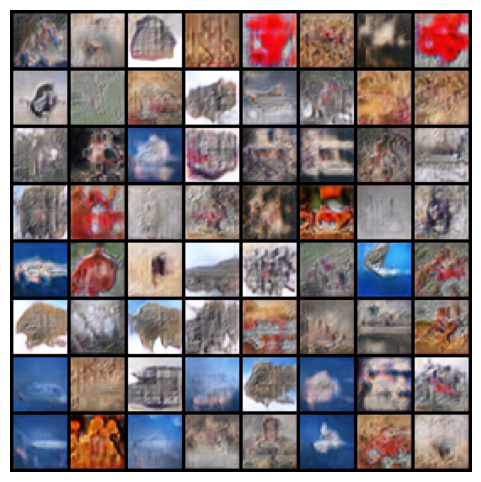

opt_steps 12500 |  loss_D 1.693 |  loss_G 0.453| D(real) +0.86±0.93 |  D(fake) +0.43±0.66 |  margins real>0.42 fake<0.03 |  ||g|| D 14.8 G 7.3 |  G(x) mean -0.06 std 0.54 range[-1.00,+1.00] |  10.3 min
opt_steps 13000 |  loss_D 1.681 |  loss_G 0.465| D(real) -0.19±0.62 |  D(fake) -0.63±0.50 |  margins real>0.08 fake<0.19 |  ||g|| D 9.1 G 6.9 |  G(x) mean -0.05 std 0.51 range[-1.00,+1.00] |  10.7 min
opt_steps 13500 |  loss_D 1.663 |  loss_G 0.470| D(real) +0.07±1.03 |  D(fake) -0.64±0.88 |  margins real>0.16 fake<0.28 |  ||g|| D 8.8 G 8.6 |  G(x) mean -0.08 std 0.52 range[-0.99,+1.00] |  11.1 min
opt_steps 14000 |  loss_D 1.634 |  loss_G 0.487| D(real) +0.08±1.21 |  D(fake) -0.68±0.66 |  margins real>0.17 fake<0.30 |  ||g|| D 11.1 G 7.2 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  11.5 min


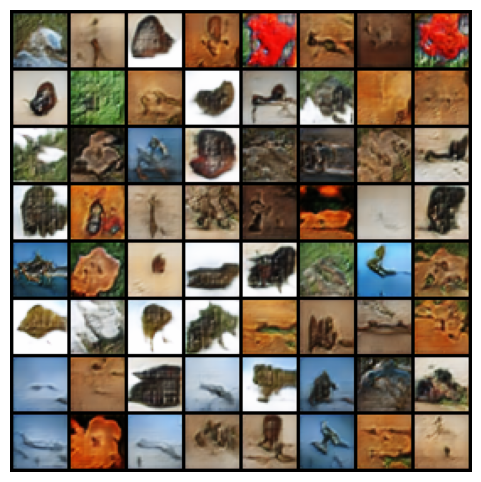

opt_steps 14500 |  loss_D 1.624 |  loss_G 0.498| D(real) -0.08±1.01 |  D(fake) -0.91±0.56 |  margins real>0.12 fake<0.41 |  ||g|| D 13.1 G 12.4 |  G(x) mean -0.06 std 0.55 range[-1.00,+1.00] |  12.0 min
opt_steps 15000 |  loss_D 1.630 |  loss_G 0.492| D(real) -0.08±1.03 |  D(fake) -0.85±0.57 |  margins real>0.09 fake<0.45 |  ||g|| D 10.9 G 11.1 |  G(x) mean -0.05 std 0.53 range[-1.00,+1.00] |  12.4 min
opt_steps 15500 |  loss_D 1.620 |  loss_G 0.497| D(real) -0.08±0.99 |  D(fake) -1.14±0.58 |  margins real>0.17 fake<0.67 |  ||g|| D 13.9 G 11.8 |  G(x) mean -0.05 std 0.51 range[-1.00,+1.00] |  12.8 min
opt_steps 16000 |  loss_D 1.613 |  loss_G 0.494| D(real) +0.43±1.01 |  D(fake) -0.38±0.62 |  margins real>0.20 fake<0.12 |  ||g|| D 10.3 G 10.6 |  G(x) mean -0.02 std 0.53 range[-1.00,+1.00] |  13.2 min


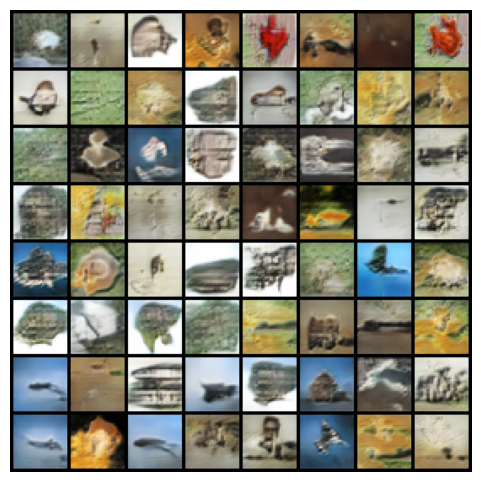

opt_steps 16500 |  loss_D 1.598 |  loss_G 0.506| D(real) -0.19±0.90 |  D(fake) -0.47±0.61 |  margins real>0.08 fake<0.22 |  ||g|| D 9.8 G 7.6 |  G(x) mean -0.07 std 0.55 range[-1.00,+1.00] |  13.6 min
opt_steps 17000 |  loss_D 1.579 |  loss_G 0.532| D(real) -0.25±0.60 |  D(fake) -0.68±0.54 |  margins real>0.02 fake<0.25 |  ||g|| D 6.7 G 7.8 |  G(x) mean -0.04 std 0.55 range[-1.00,+1.00] |  14.0 min
opt_steps 17500 |  loss_D 1.563 |  loss_G 0.530| D(real) +0.59±0.94 |  D(fake) -0.43±0.73 |  margins real>0.25 fake<0.22 |  ||g|| D 12.0 G 11.6 |  G(x) mean -0.06 std 0.54 range[-0.99,+1.00] |  14.4 min
opt_steps 18000 |  loss_D 1.557 |  loss_G 0.530| D(real) +0.68±1.17 |  D(fake) -0.34±0.61 |  margins real>0.36 fake<0.16 |  ||g|| D 9.3 G 8.3 |  G(x) mean -0.08 std 0.56 range[-1.00,+1.00] |  14.8 min


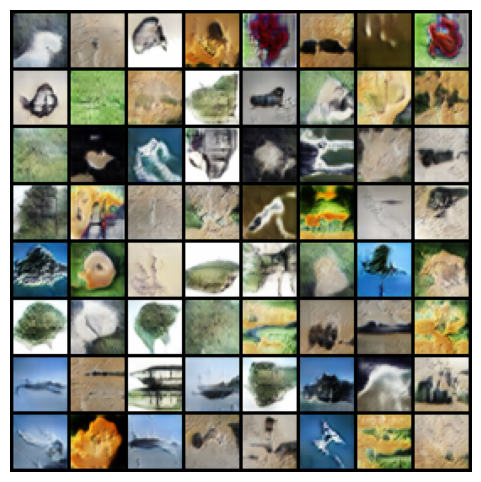

opt_steps 18500 |  loss_D 1.562 |  loss_G 0.538| D(real) +0.49±1.00 |  D(fake) -0.34±0.62 |  margins real>0.27 fake<0.14 |  ||g|| D 11.0 G 9.2 |  G(x) mean -0.03 std 0.54 range[-1.00,+1.00] |  15.2 min
opt_steps 19000 |  loss_D 1.564 |  loss_G 0.542| D(real) +0.44±0.86 |  D(fake) -0.46±0.66 |  margins real>0.25 fake<0.22 |  ||g|| D 6.9 G 8.6 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  15.6 min
opt_steps 19500 |  loss_D 1.544 |  loss_G 0.554| D(real) -0.35±0.89 |  D(fake) -1.10±0.79 |  margins real>0.09 fake<0.55 |  ||g|| D 12.6 G 10.4 |  G(x) mean -0.04 std 0.52 range[-0.99,+1.00] |  16.1 min
opt_steps 20000 |  loss_D 1.526 |  loss_G 0.558| D(real) -0.14±0.82 |  D(fake) -0.81±0.62 |  margins real>0.08 fake<0.36 |  ||g|| D 9.7 G 8.7 |  G(x) mean -0.08 std 0.51 range[-1.00,+1.00] |  16.5 min


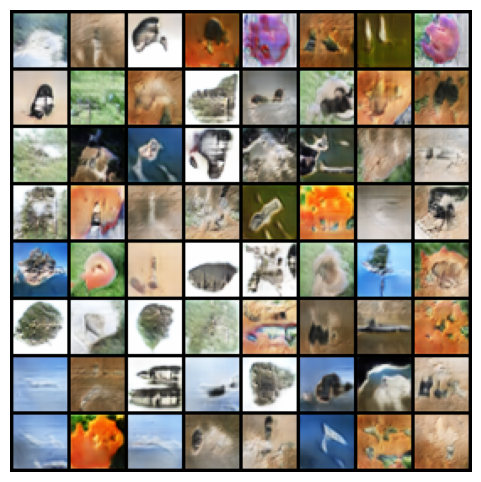

opt_steps 20500 |  loss_D 1.539 |  loss_G 0.544| D(real) -0.20±0.90 |  D(fake) -0.87±0.58 |  margins real>0.09 fake<0.44 |  ||g|| D 8.6 G 8.3 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  16.9 min
opt_steps 21000 |  loss_D 1.554 |  loss_G 0.536| D(real) +1.17±1.52 |  D(fake) +0.17±1.18 |  margins real>0.47 fake<0.08 |  ||g|| D 12.5 G 7.2 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  17.3 min
opt_steps 21500 |  loss_D 1.556 |  loss_G 0.541| D(real) +0.19±1.16 |  D(fake) -0.69±0.79 |  margins real>0.17 fake<0.36 |  ||g|| D 12.7 G 12.0 |  G(x) mean -0.05 std 0.53 range[-1.00,+1.00] |  17.7 min
opt_steps 22000 |  loss_D 1.559 |  loss_G 0.546| D(real) +0.83±1.27 |  D(fake) -0.25±1.06 |  margins real>0.36 fake<0.11 |  ||g|| D 8.9 G 10.1 |  G(x) mean -0.07 std 0.54 range[-0.99,+1.00] |  18.1 min


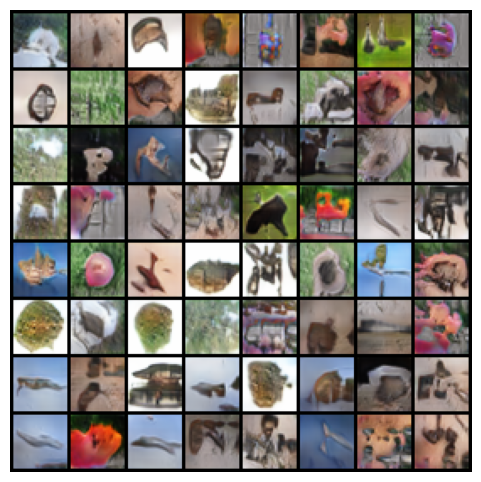

opt_steps 22500 |  loss_D 1.573 |  loss_G 0.540| D(real) +0.89±1.24 |  D(fake) -0.42±0.50 |  margins real>0.39 fake<0.11 |  ||g|| D 9.0 G 8.8 |  G(x) mean -0.02 std 0.53 range[-1.00,+1.00] |  18.5 min
opt_steps 23000 |  loss_D 1.570 |  loss_G 0.538| D(real) -0.13±0.89 |  D(fake) -0.87±0.51 |  margins real>0.11 fake<0.36 |  ||g|| D 8.3 G 8.7 |  G(x) mean -0.12 std 0.52 range[-1.00,+1.00] |  18.9 min
opt_steps 23500 |  loss_D 1.560 |  loss_G 0.538| D(real) +0.65±2.21 |  D(fake) -0.67±0.71 |  margins real>0.25 fake<0.41 |  ||g|| D 7.8 G 14.4 |  G(x) mean -0.05 std 0.52 range[-1.00,+1.00] |  19.3 min
opt_steps 24000 |  loss_D 1.549 |  loss_G 0.542| D(real) +1.28±1.31 |  D(fake) +0.60±0.97 |  margins real>0.55 fake<0.00 |  ||g|| D 23.8 G 7.4 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  19.7 min


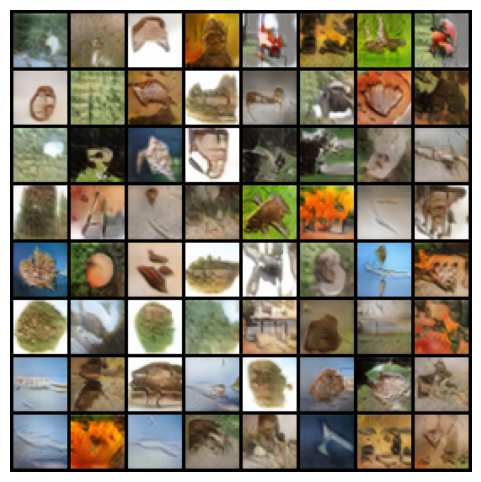

opt_steps 24500 |  loss_D 1.526 |  loss_G 0.549| D(real) +0.11±1.20 |  D(fake) -0.95±0.84 |  margins real>0.19 fake<0.55 |  ||g|| D 13.9 G 12.0 |  G(x) mean -0.08 std 0.51 range[-1.00,+1.00] |  20.2 min
opt_steps 25000 |  loss_D 1.503 |  loss_G 0.557| D(real) +0.33±1.03 |  D(fake) -0.43±0.85 |  margins real>0.25 fake<0.28 |  ||g|| D 9.6 G 10.7 |  G(x) mean -0.09 std 0.54 range[-1.00,+1.00] |  20.6 min
opt_steps 25500 |  loss_D 1.492 |  loss_G 0.570| D(real) +1.38±1.65 |  D(fake) -0.06±0.77 |  margins real>0.44 fake<0.08 |  ||g|| D 13.2 G 9.1 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  21.0 min
opt_steps 26000 |  loss_D 1.484 |  loss_G 0.580| D(real) +0.79±1.46 |  D(fake) -0.48±0.81 |  margins real>0.31 fake<0.30 |  ||g|| D 12.3 G 9.3 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  21.4 min


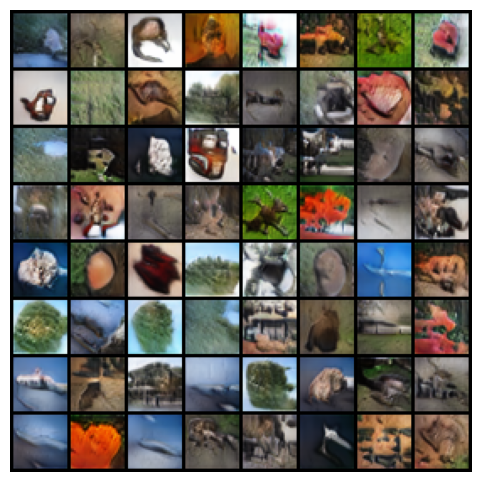

opt_steps 26500 |  loss_D 1.477 |  loss_G 0.579| D(real) +0.61±1.24 |  D(fake) -0.34±0.83 |  margins real>0.27 fake<0.20 |  ||g|| D 8.7 G 9.7 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  21.8 min
opt_steps 27000 |  loss_D 1.470 |  loss_G 0.576| D(real) +0.72±1.52 |  D(fake) -0.34±0.89 |  margins real>0.31 fake<0.20 |  ||g|| D 16.1 G 12.1 |  G(x) mean -0.03 std 0.54 range[-1.00,+1.00] |  22.2 min
opt_steps 27500 |  loss_D 1.469 |  loss_G 0.589| D(real) -0.19±0.84 |  D(fake) -0.94±0.54 |  margins real>0.08 fake<0.44 |  ||g|| D 12.4 G 10.1 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  22.6 min
opt_steps 28000 |  loss_D 1.474 |  loss_G 0.585| D(real) -0.67±1.14 |  D(fake) -1.64±0.68 |  margins real>0.09 fake<0.84 |  ||g|| D 13.4 G 10.6 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  23.1 min


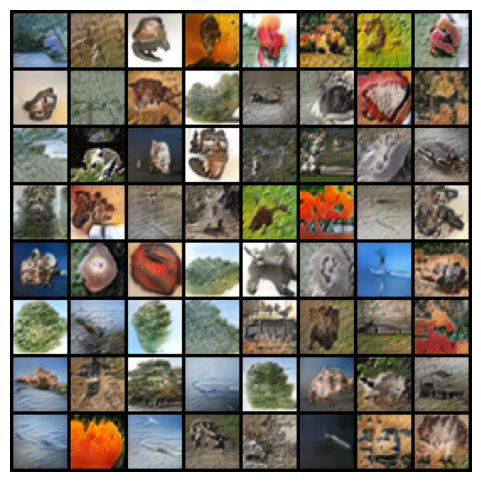

opt_steps 28500 |  loss_D 1.451 |  loss_G 0.596| D(real) +0.49±0.98 |  D(fake) -0.70±0.81 |  margins real>0.25 fake<0.45 |  ||g|| D 13.3 G 11.5 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  23.5 min
opt_steps 29000 |  loss_D 1.423 |  loss_G 0.619| D(real) +0.07±1.08 |  D(fake) -0.95±0.55 |  margins real>0.20 fake<0.50 |  ||g|| D 15.0 G 11.3 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  23.9 min
opt_steps 29500 |  loss_D 1.432 |  loss_G 0.613| D(real) -0.07±1.10 |  D(fake) -1.26±0.78 |  margins real>0.14 fake<0.66 |  ||g|| D 16.7 G 11.9 |  G(x) mean -0.06 std 0.52 range[-1.00,+1.00] |  24.3 min
opt_steps 30000 |  loss_D 1.433 |  loss_G 0.607| D(real) +1.06±1.50 |  D(fake) -0.16±0.80 |  margins real>0.44 fake<0.12 |  ||g|| D 12.6 G 9.7 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  24.7 min


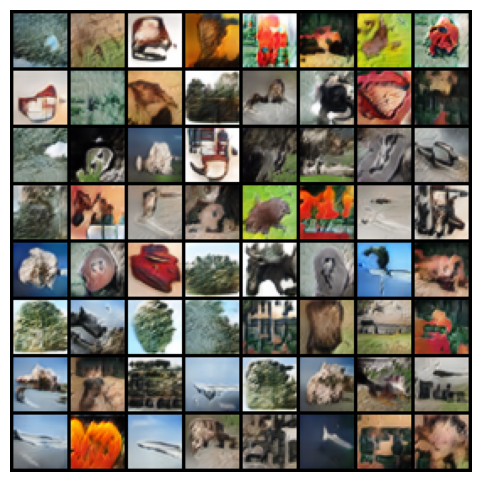

opt_steps 30500 |  loss_D 1.411 |  loss_G 0.623| D(real) +0.86±1.71 |  D(fake) -0.28±0.79 |  margins real>0.38 fake<0.16 |  ||g|| D 11.4 G 10.4 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  25.1 min
opt_steps 31000 |  loss_D 1.418 |  loss_G 0.623| D(real) +0.65±0.98 |  D(fake) -0.15±0.81 |  margins real>0.28 fake<0.14 |  ||g|| D 11.2 G 11.5 |  G(x) mean -0.12 std 0.51 range[-1.00,+1.00] |  25.5 min
opt_steps 31500 |  loss_D 1.421 |  loss_G 0.621| D(real) +0.71±1.86 |  D(fake) -0.72±0.74 |  margins real>0.31 fake<0.38 |  ||g|| D 8.8 G 10.9 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  26.0 min
opt_steps 32000 |  loss_D 1.414 |  loss_G 0.630| D(real) +0.47±1.33 |  D(fake) -0.64±0.65 |  margins real>0.30 fake<0.31 |  ||g|| D 10.1 G 12.5 |  G(x) mean -0.04 std 0.52 range[-1.00,+1.00] |  26.4 min


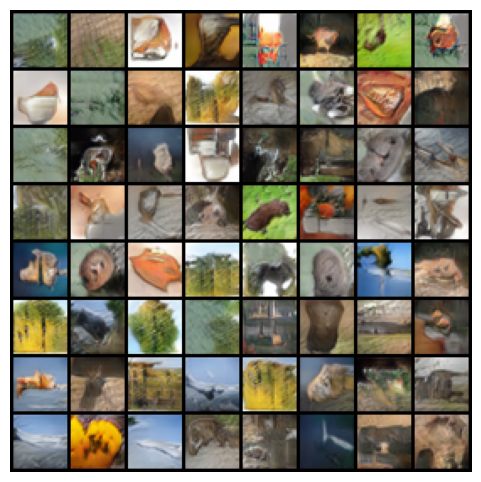

opt_steps 32500 |  loss_D 1.406 |  loss_G 0.642| D(real) +0.87±1.41 |  D(fake) -0.58±0.71 |  margins real>0.41 fake<0.31 |  ||g|| D 12.6 G 11.8 |  G(x) mean -0.03 std 0.54 range[-1.00,+1.00] |  26.8 min
opt_steps 33000 |  loss_D 1.400 |  loss_G 0.640| D(real) +0.57±2.19 |  D(fake) -0.82±0.74 |  margins real>0.28 fake<0.38 |  ||g|| D 15.7 G 13.6 |  G(x) mean -0.07 std 0.55 range[-1.00,+1.00] |  27.2 min
opt_steps 33500 |  loss_D 1.387 |  loss_G 0.649| D(real) +0.37±1.32 |  D(fake) -0.55±0.81 |  margins real>0.20 fake<0.34 |  ||g|| D 13.8 G 12.8 |  G(x) mean -0.12 std 0.50 range[-1.00,+1.00] |  27.6 min
opt_steps 34000 |  loss_D 1.399 |  loss_G 0.650| D(real) +0.56±1.15 |  D(fake) -0.64±0.92 |  margins real>0.31 fake<0.38 |  ||g|| D 10.8 G 11.6 |  G(x) mean -0.05 std 0.51 range[-1.00,+1.00] |  28.0 min


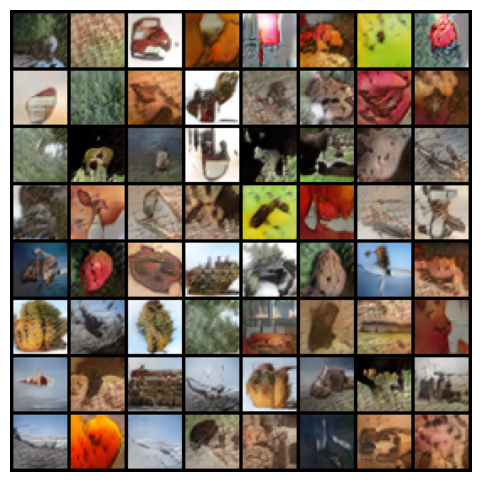

opt_steps 34500 |  loss_D 1.412 |  loss_G 0.640| D(real) +1.72±1.74 |  D(fake) +0.12±1.03 |  margins real>0.61 fake<0.19 |  ||g|| D 18.6 G 9.4 |  G(x) mean -0.08 std 0.51 range[-1.00,+1.00] |  28.4 min
opt_steps 35000 |  loss_D 1.376 |  loss_G 0.679| D(real) -0.16±1.15 |  D(fake) -1.09±0.84 |  margins real>0.11 fake<0.50 |  ||g|| D 14.4 G 10.9 |  G(x) mean -0.07 std 0.51 range[-1.00,+1.00] |  28.8 min
opt_steps 35500 |  loss_D 1.367 |  loss_G 0.693| D(real) -0.06±1.00 |  D(fake) -0.89±0.73 |  margins real>0.14 fake<0.42 |  ||g|| D 13.6 G 10.5 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  29.2 min
opt_steps 36000 |  loss_D 1.373 |  loss_G 0.673| D(real) +0.28±1.38 |  D(fake) -0.86±0.73 |  margins real>0.30 fake<0.47 |  ||g|| D 12.8 G 10.1 |  G(x) mean -0.05 std 0.51 range[-1.00,+1.00] |  29.7 min


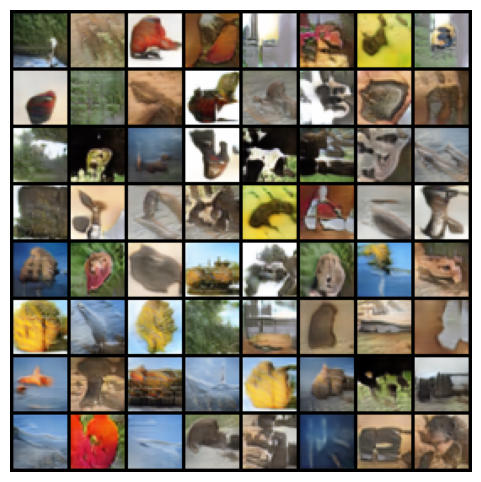

opt_steps 36500 |  loss_D 1.356 |  loss_G 0.681| D(real) +0.76±1.79 |  D(fake) -0.81±0.76 |  margins real>0.33 fake<0.36 |  ||g|| D 11.4 G 13.5 |  G(x) mean -0.09 std 0.54 range[-1.00,+1.00] |  30.1 min
opt_steps 37000 |  loss_D 1.348 |  loss_G 0.699| D(real) +1.43±2.19 |  D(fake) -0.51±0.67 |  margins real>0.47 fake<0.27 |  ||g|| D 11.5 G 11.0 |  G(x) mean -0.08 std 0.53 range[-0.99,+1.00] |  30.5 min
opt_steps 37500 |  loss_D 1.357 |  loss_G 0.699| D(real) +0.86±1.55 |  D(fake) -0.76±0.93 |  margins real>0.42 fake<0.33 |  ||g|| D 14.7 G 11.5 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  30.9 min
opt_steps 38000 |  loss_D 1.356 |  loss_G 0.700| D(real) +0.59±1.30 |  D(fake) -0.39±0.82 |  margins real>0.39 fake<0.20 |  ||g|| D 11.0 G 9.1 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  31.3 min


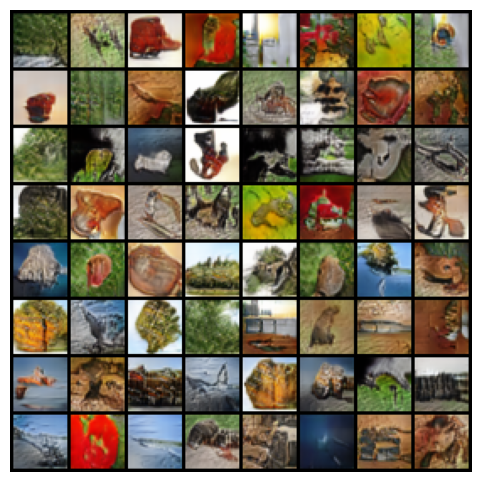

opt_steps 38500 |  loss_D 1.342 |  loss_G 0.697| D(real) +1.99±2.23 |  D(fake) -0.23±0.92 |  margins real>0.56 fake<0.22 |  ||g|| D 14.2 G 12.7 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  31.7 min
opt_steps 39000 |  loss_D 1.330 |  loss_G 0.696| D(real) -0.22±1.51 |  D(fake) -1.49±0.71 |  margins real>0.16 fake<0.78 |  ||g|| D 17.1 G 11.7 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  32.1 min
opt_steps 39500 |  loss_D 1.323 |  loss_G 0.708| D(real) +1.01±1.67 |  D(fake) -0.63±0.85 |  margins real>0.44 fake<0.36 |  ||g|| D 11.0 G 10.7 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  32.5 min
opt_steps 40000 |  loss_D 1.312 |  loss_G 0.715| D(real) +0.38±1.68 |  D(fake) -0.98±0.54 |  margins real>0.25 fake<0.47 |  ||g|| D 9.6 G 9.4 |  G(x) mean -0.04 std 0.52 range[-1.00,+1.00] |  32.9 min


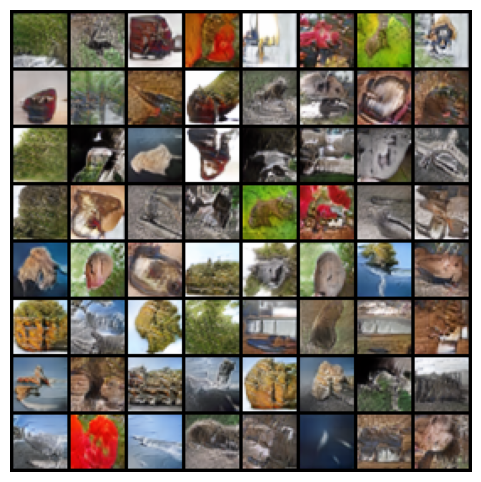

opt_steps 40500 |  loss_D 1.315 |  loss_G 0.698| D(real) +0.34±1.69 |  D(fake) -1.01±0.72 |  margins real>0.23 fake<0.45 |  ||g|| D 14.2 G 13.1 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  33.4 min
opt_steps 41000 |  loss_D 1.320 |  loss_G 0.703| D(real) +2.17±2.64 |  D(fake) -0.04±0.89 |  margins real>0.67 fake<0.11 |  ||g|| D 23.0 G 11.6 |  G(x) mean -0.05 std 0.52 range[-0.99,+1.00] |  33.8 min
opt_steps 41500 |  loss_D 1.310 |  loss_G 0.724| D(real) +1.42±1.55 |  D(fake) -0.38±0.89 |  margins real>0.53 fake<0.30 |  ||g|| D 17.0 G 11.4 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  34.2 min
opt_steps 42000 |  loss_D 1.306 |  loss_G 0.721| D(real) +1.75±2.03 |  D(fake) -0.20±0.97 |  margins real>0.59 fake<0.12 |  ||g|| D 15.7 G 9.1 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  34.6 min


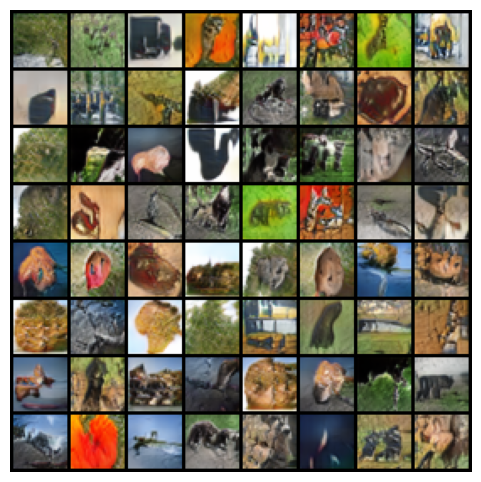

opt_steps 42500 |  loss_D 1.302 |  loss_G 0.712| D(real) +1.21±2.05 |  D(fake) -0.20±0.80 |  margins real>0.45 fake<0.14 |  ||g|| D 20.2 G 10.0 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  35.0 min
opt_steps 43000 |  loss_D 1.298 |  loss_G 0.716| D(real) +0.70±1.72 |  D(fake) -0.76±0.71 |  margins real>0.34 fake<0.38 |  ||g|| D 13.2 G 11.8 |  G(x) mean -0.08 std 0.51 range[-0.99,+1.00] |  35.4 min
opt_steps 43500 |  loss_D 1.302 |  loss_G 0.727| D(real) +0.57±1.46 |  D(fake) -0.69±0.91 |  margins real>0.34 fake<0.39 |  ||g|| D 14.8 G 10.9 |  G(x) mean -0.09 std 0.51 range[-1.00,+1.00] |  35.8 min
opt_steps 44000 |  loss_D 1.293 |  loss_G 0.721| D(real) +1.22±1.70 |  D(fake) -0.57±0.75 |  margins real>0.52 fake<0.23 |  ||g|| D 14.2 G 13.2 |  G(x) mean -0.08 std 0.53 range[-1.00,+1.00] |  36.2 min


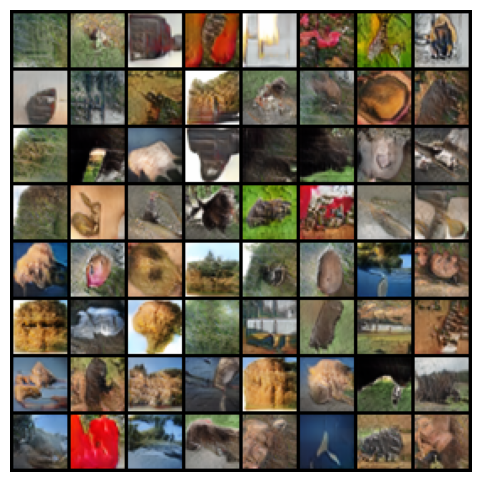

opt_steps 44500 |  loss_D 1.276 |  loss_G 0.726| D(real) +1.39±1.49 |  D(fake) +0.29±1.14 |  margins real>0.58 fake<0.11 |  ||g|| D 18.4 G 10.2 |  G(x) mean -0.07 std 0.54 range[-1.00,+1.00] |  36.7 min
opt_steps 45000 |  loss_D 1.263 |  loss_G 0.755| D(real) +1.25±3.07 |  D(fake) -0.73±0.73 |  margins real>0.38 fake<0.33 |  ||g|| D 12.9 G 11.4 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  37.1 min
opt_steps 45500 |  loss_D 1.250 |  loss_G 0.768| D(real) +1.96±2.02 |  D(fake) -0.12±0.90 |  margins real>0.64 fake<0.19 |  ||g|| D 25.2 G 10.8 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  37.5 min
opt_steps 46000 |  loss_D 1.258 |  loss_G 0.753| D(real) +0.71±1.60 |  D(fake) -0.98±0.67 |  margins real>0.31 fake<0.47 |  ||g|| D 11.5 G 13.6 |  G(x) mean -0.06 std 0.53 range[-1.00,+1.00] |  37.9 min


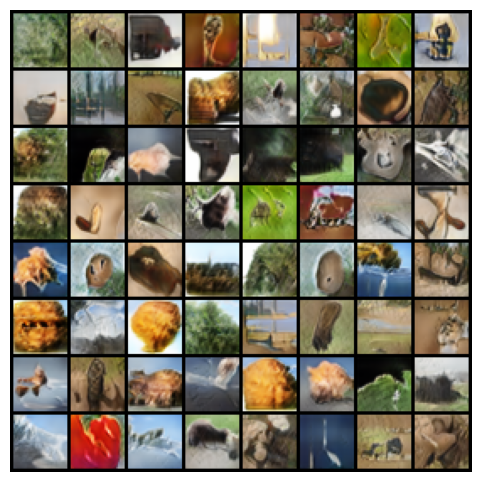

opt_steps 46500 |  loss_D 1.269 |  loss_G 0.747| D(real) +0.59±1.20 |  D(fake) -0.76±0.96 |  margins real>0.28 fake<0.42 |  ||g|| D 14.0 G 14.0 |  G(x) mean -0.07 std 0.51 range[-1.00,+1.00] |  38.3 min
opt_steps 47000 |  loss_D 1.268 |  loss_G 0.753| D(real) +1.70±2.40 |  D(fake) -0.69±0.93 |  margins real>0.50 fake<0.34 |  ||g|| D 12.4 G 12.8 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  38.7 min
opt_steps 47500 |  loss_D 1.261 |  loss_G 0.757| D(real) -0.64±1.16 |  D(fake) -1.58±0.77 |  margins real>0.08 fake<0.72 |  ||g|| D 15.3 G 11.3 |  G(x) mean -0.11 std 0.48 range[-1.00,+1.00] |  39.1 min
opt_steps 48000 |  loss_D 1.260 |  loss_G 0.752| D(real) +1.76±1.95 |  D(fake) -0.42±0.93 |  margins real>0.58 fake<0.28 |  ||g|| D 12.1 G 13.9 |  G(x) mean -0.09 std 0.51 range[-1.00,+1.00] |  39.5 min


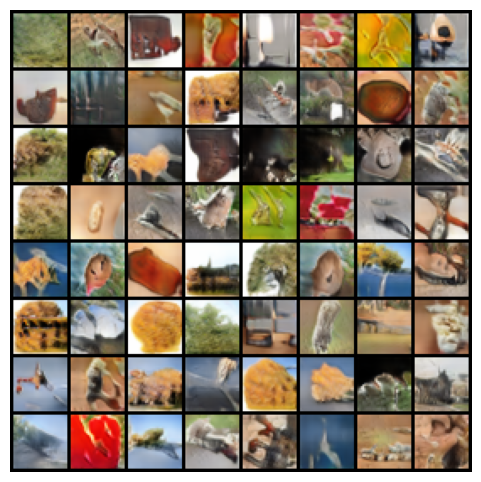

opt_steps 48500 |  loss_D 1.248 |  loss_G 0.762| D(real) +1.46±2.21 |  D(fake) -0.46±0.73 |  margins real>0.48 fake<0.28 |  ||g|| D 11.1 G 13.4 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  40.0 min
opt_steps 49000 |  loss_D 1.241 |  loss_G 0.774| D(real) +0.26±1.31 |  D(fake) -0.92±0.80 |  margins real>0.30 fake<0.47 |  ||g|| D 14.9 G 10.9 |  G(x) mean -0.07 std 0.54 range[-1.00,+1.00] |  40.4 min
opt_steps 49500 |  loss_D 1.240 |  loss_G 0.779| D(real) +0.94±1.74 |  D(fake) -0.51±0.82 |  margins real>0.39 fake<0.28 |  ||g|| D 13.3 G 12.7 |  G(x) mean -0.08 std 0.54 range[-1.00,+1.00] |  40.8 min
opt_steps 50000 |  loss_D 1.236 |  loss_G 0.781| D(real) +1.63±2.00 |  D(fake) -0.37±0.87 |  margins real>0.55 fake<0.22 |  ||g|| D 15.3 G 10.5 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  41.2 min


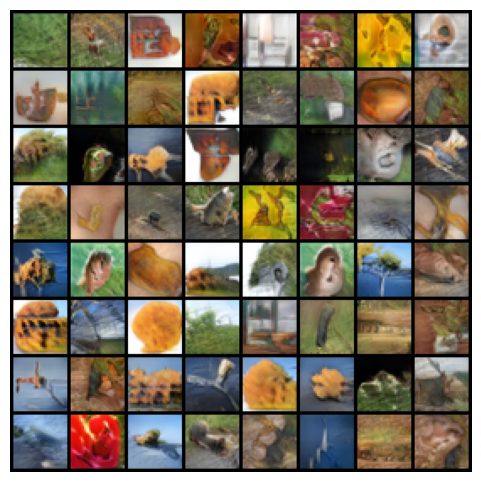

opt_steps 50500 |  loss_D 1.233 |  loss_G 0.775| D(real) +2.12±1.90 |  D(fake) +0.22±1.02 |  margins real>0.67 fake<0.11 |  ||g|| D 18.8 G 9.3 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  41.6 min
opt_steps 51000 |  loss_D 1.229 |  loss_G 0.781| D(real) +1.09±1.84 |  D(fake) -0.52±0.90 |  margins real>0.39 fake<0.28 |  ||g|| D 12.1 G 11.7 |  G(x) mean -0.05 std 0.55 range[-1.00,+1.00] |  42.0 min
opt_steps 51500 |  loss_D 1.234 |  loss_G 0.776| D(real) +0.92±1.58 |  D(fake) -0.48±0.79 |  margins real>0.41 fake<0.17 |  ||g|| D 14.3 G 10.4 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  42.4 min
opt_steps 52000 |  loss_D 1.231 |  loss_G 0.783| D(real) +0.55±1.31 |  D(fake) -0.82±1.22 |  margins real>0.27 fake<0.44 |  ||g|| D 14.9 G 14.2 |  G(x) mean -0.03 std 0.55 range[-1.00,+1.00] |  42.8 min


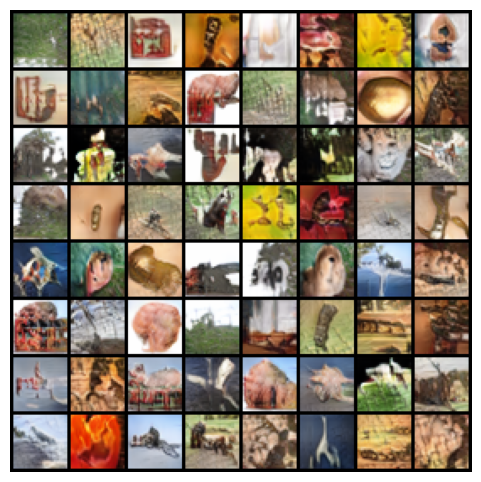

opt_steps 52500 |  loss_D 1.223 |  loss_G 0.802| D(real) +0.49±1.54 |  D(fake) -0.87±1.03 |  margins real>0.31 fake<0.52 |  ||g|| D 12.5 G 17.5 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  43.2 min
opt_steps 53000 |  loss_D 1.210 |  loss_G 0.800| D(real) +0.61±1.74 |  D(fake) -1.13±0.76 |  margins real>0.28 fake<0.58 |  ||g|| D 16.6 G 16.3 |  G(x) mean -0.10 std 0.50 range[-1.00,+1.00] |  43.7 min
opt_steps 53500 |  loss_D 1.198 |  loss_G 0.818| D(real) +1.84±2.26 |  D(fake) +0.28±1.15 |  margins real>0.59 fake<0.12 |  ||g|| D 19.1 G 11.1 |  G(x) mean -0.04 std 0.54 range[-1.00,+1.00] |  44.1 min
opt_steps 54000 |  loss_D 1.204 |  loss_G 0.833| D(real) +1.27±2.44 |  D(fake) -0.80±1.10 |  margins real>0.36 fake<0.45 |  ||g|| D 15.8 G 14.0 |  G(x) mean -0.13 std 0.51 range[-1.00,+1.00] |  44.5 min


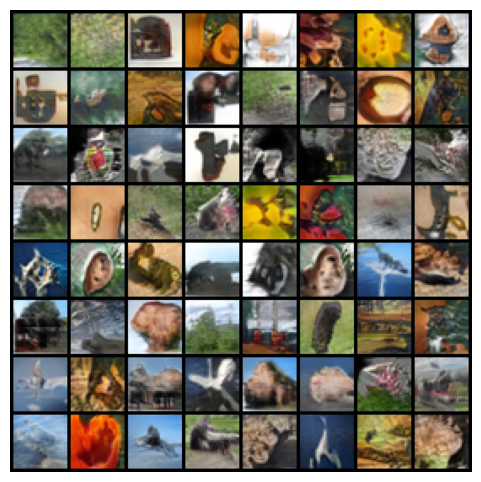

opt_steps 54500 |  loss_D 1.209 |  loss_G 0.824| D(real) +0.93±1.87 |  D(fake) -0.80±0.86 |  margins real>0.34 fake<0.41 |  ||g|| D 18.0 G 16.3 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  44.9 min
opt_steps 55000 |  loss_D 1.208 |  loss_G 0.822| D(real) +1.42±2.31 |  D(fake) -0.91±0.82 |  margins real>0.52 fake<0.45 |  ||g|| D 9.1 G 13.2 |  G(x) mean -0.07 std 0.53 range[-1.00,+1.00] |  45.3 min
opt_steps 55500 |  loss_D 1.196 |  loss_G 0.828| D(real) +0.62±2.12 |  D(fake) -1.19±0.73 |  margins real>0.23 fake<0.59 |  ||g|| D 14.8 G 16.0 |  G(x) mean -0.12 std 0.48 range[-1.00,+1.00] |  45.7 min
opt_steps 56000 |  loss_D 1.197 |  loss_G 0.825| D(real) +0.12±2.18 |  D(fake) -1.37±0.78 |  margins real>0.23 fake<0.77 |  ||g|| D 15.8 G 12.8 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  46.1 min


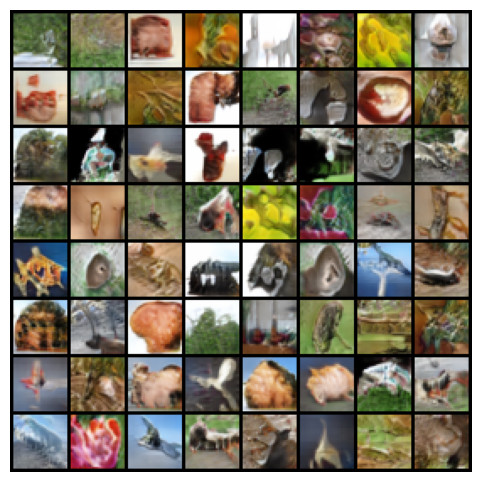

opt_steps 56500 |  loss_D 1.206 |  loss_G 0.816| D(real) +1.01±1.85 |  D(fake) -0.82±0.78 |  margins real>0.39 fake<0.38 |  ||g|| D 15.0 G 11.9 |  G(x) mean -0.08 std 0.49 range[-1.00,+1.00] |  46.5 min
opt_steps 57000 |  loss_D 1.184 |  loss_G 0.826| D(real) +0.47±1.81 |  D(fake) -1.31±0.67 |  margins real>0.31 fake<0.73 |  ||g|| D 14.7 G 14.0 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  46.9 min
opt_steps 57500 |  loss_D 1.185 |  loss_G 0.829| D(real) +1.18±1.75 |  D(fake) -0.98±0.88 |  margins real>0.50 fake<0.47 |  ||g|| D 12.3 G 13.1 |  G(x) mean -0.10 std 0.50 range[-1.00,+1.00] |  47.3 min
opt_steps 58000 |  loss_D 1.203 |  loss_G 0.825| D(real) +1.06±2.08 |  D(fake) -0.98±0.85 |  margins real>0.39 fake<0.59 |  ||g|| D 11.9 G 16.0 |  G(x) mean -0.07 std 0.53 range[-1.00,+1.00] |  47.8 min


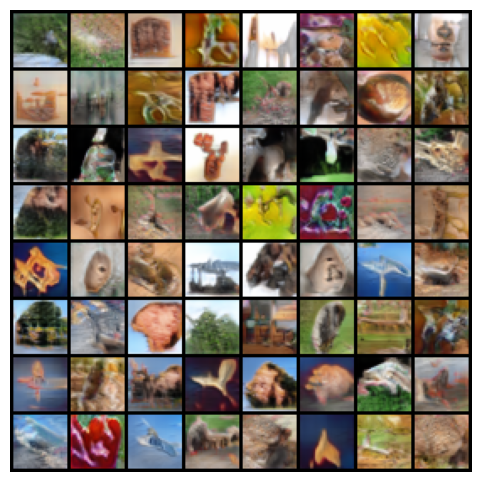

opt_steps 58500 |  loss_D 1.209 |  loss_G 0.816| D(real) +1.49±1.74 |  D(fake) -0.37±1.10 |  margins real>0.55 fake<0.28 |  ||g|| D 18.1 G 12.0 |  G(x) mean -0.09 std 0.54 range[-1.00,+1.00] |  48.2 min
opt_steps 59000 |  loss_D 1.184 |  loss_G 0.839| D(real) +1.88±2.57 |  D(fake) -0.54±0.96 |  margins real>0.53 fake<0.34 |  ||g|| D 14.8 G 13.4 |  G(x) mean -0.07 std 0.50 range[-1.00,+1.00] |  48.6 min
opt_steps 59500 |  loss_D 1.164 |  loss_G 0.847| D(real) +2.24±2.67 |  D(fake) -0.39±1.04 |  margins real>0.66 fake<0.25 |  ||g|| D 14.9 G 11.3 |  G(x) mean -0.10 std 0.50 range[-0.99,+1.00] |  49.0 min
opt_steps 60000 |  loss_D 1.171 |  loss_G 0.833| D(real) +3.11±3.40 |  D(fake) -0.20±1.31 |  margins real>0.73 fake<0.27 |  ||g|| D 18.7 G 14.7 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  49.4 min


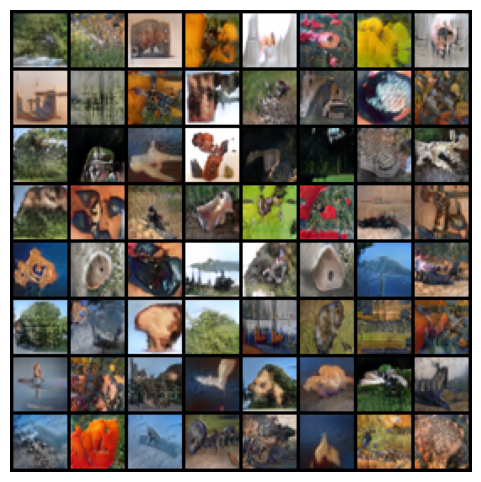

opt_steps 60500 |  loss_D 1.163 |  loss_G 0.847| D(real) +1.16±2.06 |  D(fake) -0.84±0.82 |  margins real>0.38 fake<0.42 |  ||g|| D 11.8 G 13.2 |  G(x) mean -0.10 std 0.50 range[-1.00,+1.00] |  49.9 min
opt_steps 61000 |  loss_D 1.165 |  loss_G 0.853| D(real) +1.26±2.10 |  D(fake) -0.91±0.94 |  margins real>0.42 fake<0.45 |  ||g|| D 11.6 G 14.3 |  G(x) mean -0.12 std 0.51 range[-1.00,+1.00] |  50.3 min
opt_steps 61500 |  loss_D 1.160 |  loss_G 0.853| D(real) +1.32±2.18 |  D(fake) -0.68±1.09 |  margins real>0.53 fake<0.34 |  ||g|| D 16.8 G 14.2 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  50.7 min
opt_steps 62000 |  loss_D 1.174 |  loss_G 0.841| D(real) +2.17±2.52 |  D(fake) -0.05±1.01 |  margins real>0.62 fake<0.17 |  ||g|| D 18.4 G 12.0 |  G(x) mean -0.09 std 0.50 range[-1.00,+1.00] |  51.1 min


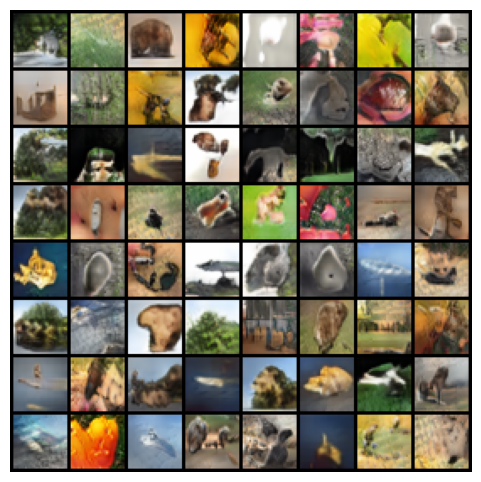

opt_steps 62500 |  loss_D 1.178 |  loss_G 0.849| D(real) +2.19±2.56 |  D(fake) -0.39±1.04 |  margins real>0.59 fake<0.28 |  ||g|| D 14.3 G 10.3 |  G(x) mean -0.08 std 0.50 range[-1.00,+1.00] |  51.5 min
opt_steps 63000 |  loss_D 1.171 |  loss_G 0.846| D(real) +1.88±2.21 |  D(fake) -0.33±1.01 |  margins real>0.62 fake<0.23 |  ||g|| D 17.8 G 12.8 |  G(x) mean -0.09 std 0.50 range[-1.00,+1.00] |  52.0 min
opt_steps 63500 |  loss_D 1.174 |  loss_G 0.838| D(real) +2.12±2.86 |  D(fake) -0.69±1.10 |  margins real>0.62 fake<0.42 |  ||g|| D 12.5 G 13.3 |  G(x) mean -0.08 std 0.53 range[-1.00,+1.00] |  52.4 min
opt_steps 64000 |  loss_D 1.170 |  loss_G 0.839| D(real) +0.33±2.03 |  D(fake) -1.12±0.92 |  margins real>0.23 fake<0.53 |  ||g|| D 13.9 G 13.4 |  G(x) mean -0.11 std 0.54 range[-1.00,+1.00] |  52.8 min


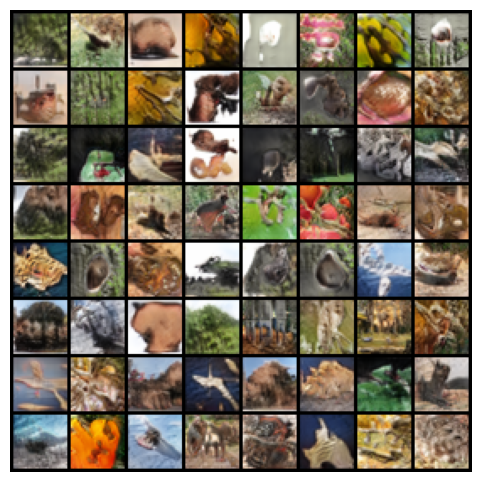

opt_steps 64500 |  loss_D 1.180 |  loss_G 0.826| D(real) +2.12±2.14 |  D(fake) -0.51±1.18 |  margins real>0.69 fake<0.41 |  ||g|| D 17.1 G 12.2 |  G(x) mean -0.07 std 0.53 range[-1.00,+1.00] |  53.2 min
opt_steps 65000 |  loss_D 1.182 |  loss_G 0.843| D(real) +1.14±2.04 |  D(fake) -0.57±0.99 |  margins real>0.39 fake<0.30 |  ||g|| D 16.3 G 13.6 |  G(x) mean -0.08 std 0.51 range[-1.00,+1.00] |  53.6 min
opt_steps 65500 |  loss_D 1.187 |  loss_G 0.849| D(real) +1.81±2.39 |  D(fake) -0.46±0.85 |  margins real>0.55 fake<0.28 |  ||g|| D 16.8 G 14.0 |  G(x) mean -0.07 std 0.51 range[-1.00,+1.00] |  54.0 min
opt_steps 66000 |  loss_D 1.189 |  loss_G 0.839| D(real) +1.74±2.74 |  D(fake) -0.77±0.91 |  margins real>0.55 fake<0.41 |  ||g|| D 12.2 G 14.9 |  G(x) mean -0.10 std 0.53 range[-1.00,+1.00] |  54.4 min


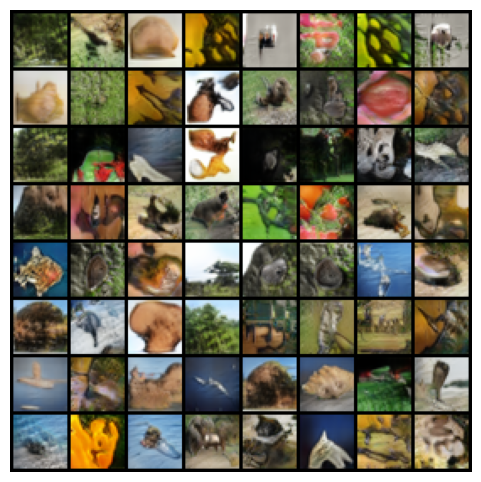

opt_steps 66500 |  loss_D 1.193 |  loss_G 0.827| D(real) +1.51±1.95 |  D(fake) -0.44±0.87 |  margins real>0.50 fake<0.30 |  ||g|| D 13.7 G 14.0 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  54.9 min
opt_steps 67000 |  loss_D 1.195 |  loss_G 0.824| D(real) +0.68±1.29 |  D(fake) -1.17±0.69 |  margins real>0.33 fake<0.64 |  ||g|| D 15.2 G 14.5 |  G(x) mean -0.08 std 0.53 range[-1.00,+1.00] |  55.3 min
opt_steps 67500 |  loss_D 1.175 |  loss_G 0.853| D(real) +0.15±1.25 |  D(fake) -1.03±0.89 |  margins real>0.19 fake<0.59 |  ||g|| D 20.2 G 14.0 |  G(x) mean -0.09 std 0.49 range[-1.00,+1.00] |  55.7 min
opt_steps 68000 |  loss_D 1.162 |  loss_G 0.862| D(real) +1.95±3.52 |  D(fake) -0.61±1.19 |  margins real>0.47 fake<0.42 |  ||g|| D 13.4 G 13.9 |  G(x) mean -0.07 std 0.52 range[-1.00,+1.00] |  56.1 min


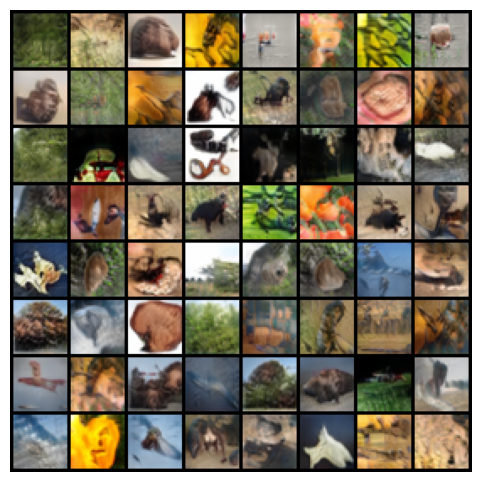

opt_steps 68500 |  loss_D 1.159 |  loss_G 0.851| D(real) +0.58±1.48 |  D(fake) -1.50±0.78 |  margins real>0.34 fake<0.77 |  ||g|| D 13.7 G 15.1 |  G(x) mean -0.11 std 0.50 range[-1.00,+1.00] |  56.5 min
opt_steps 69000 |  loss_D 1.146 |  loss_G 0.871| D(real) +0.87±2.25 |  D(fake) -1.48±0.73 |  margins real>0.33 fake<0.73 |  ||g|| D 19.3 G 17.8 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  57.0 min
opt_steps 69500 |  loss_D 1.143 |  loss_G 0.873| D(real) +1.42±1.80 |  D(fake) -1.02±0.67 |  margins real>0.59 fake<0.45 |  ||g|| D 10.0 G 13.8 |  G(x) mean -0.08 std 0.53 range[-1.00,+1.00] |  57.4 min
opt_steps 70000 |  loss_D 1.146 |  loss_G 0.871| D(real) +0.72±1.76 |  D(fake) -0.86±0.92 |  margins real>0.38 fake<0.38 |  ||g|| D 14.7 G 11.3 |  G(x) mean -0.09 std 0.51 range[-1.00,+1.00] |  57.8 min


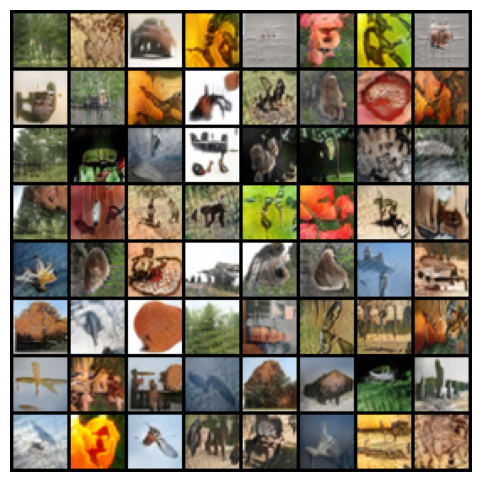

opt_steps 70500 |  loss_D 1.155 |  loss_G 0.863| D(real) +2.02±2.37 |  D(fake) -0.10±1.21 |  margins real>0.56 fake<0.19 |  ||g|| D 19.2 G 11.6 |  G(x) mean -0.07 std 0.50 range[-1.00,+1.00] |  58.2 min
opt_steps 71000 |  loss_D 1.157 |  loss_G 0.851| D(real) +1.60±2.18 |  D(fake) -0.34±0.79 |  margins real>0.48 fake<0.25 |  ||g|| D 15.2 G 13.3 |  G(x) mean -0.11 std 0.49 range[-1.00,+1.00] |  58.6 min
opt_steps 71500 |  loss_D 1.137 |  loss_G 0.870| D(real) +2.04±2.71 |  D(fake) -1.01±0.73 |  margins real>0.52 fake<0.50 |  ||g|| D 11.5 G 15.2 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  59.0 min
opt_steps 72000 |  loss_D 1.142 |  loss_G 0.856| D(real) +2.12±3.07 |  D(fake) -0.42±0.86 |  margins real>0.56 fake<0.17 |  ||g|| D 18.3 G 9.9 |  G(x) mean -0.12 std 0.53 range[-0.99,+1.00] |  59.4 min


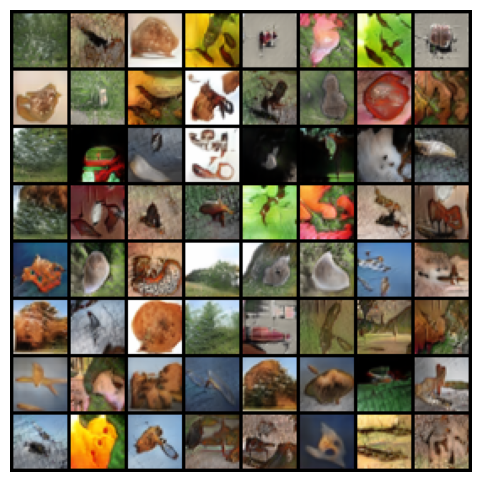

opt_steps 72500 |  loss_D 1.144 |  loss_G 0.856| D(real) +1.95±2.35 |  D(fake) -0.44±0.86 |  margins real>0.61 fake<0.30 |  ||g|| D 19.3 G 10.9 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  59.9 min
opt_steps 73000 |  loss_D 1.141 |  loss_G 0.869| D(real) +0.84±1.91 |  D(fake) -0.95±1.04 |  margins real>0.38 fake<0.53 |  ||g|| D 18.6 G 19.1 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  60.3 min
opt_steps 73500 |  loss_D 1.149 |  loss_G 0.855| D(real) +1.43±2.54 |  D(fake) -0.86±1.09 |  margins real>0.50 fake<0.53 |  ||g|| D 12.1 G 13.0 |  G(x) mean -0.08 std 0.53 range[-1.00,+1.00] |  60.7 min
opt_steps 74000 |  loss_D 1.163 |  loss_G 0.835| D(real) +0.61±2.04 |  D(fake) -1.33±0.86 |  margins real>0.38 fake<0.70 |  ||g|| D 13.1 G 13.1 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  61.1 min


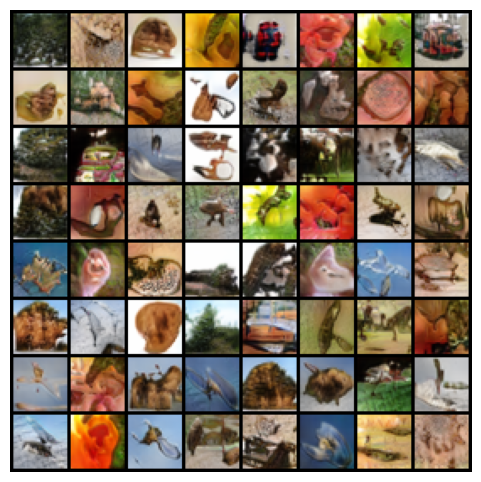

opt_steps 74500 |  loss_D 1.155 |  loss_G 0.844| D(real) +2.05±3.64 |  D(fake) -0.53±0.89 |  margins real>0.47 fake<0.23 |  ||g|| D 12.7 G 12.4 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  61.5 min
opt_steps 75000 |  loss_D 1.131 |  loss_G 0.873| D(real) +1.38±1.78 |  D(fake) -0.47±0.96 |  margins real>0.56 fake<0.31 |  ||g|| D 13.8 G 12.6 |  G(x) mean -0.08 std 0.51 range[-1.00,+1.00] |  61.9 min
opt_steps 75500 |  loss_D 1.142 |  loss_G 0.877| D(real) +0.98±2.05 |  D(fake) -1.25±0.80 |  margins real>0.44 fake<0.55 |  ||g|| D 11.4 G 12.6 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  62.4 min
opt_steps 76000 |  loss_D 1.161 |  loss_G 0.862| D(real) +0.64±1.95 |  D(fake) -1.31±0.86 |  margins real>0.30 fake<0.67 |  ||g|| D 16.3 G 14.9 |  G(x) mean -0.11 std 0.52 range[-1.00,+1.00] |  62.8 min


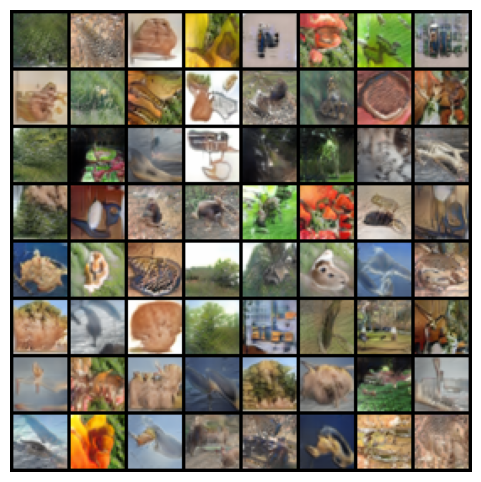

opt_steps 76500 |  loss_D 1.166 |  loss_G 0.840| D(real) +0.40±2.15 |  D(fake) -1.70±0.74 |  margins real>0.30 fake<0.89 |  ||g|| D 23.0 G 15.4 |  G(x) mean -0.09 std 0.50 range[-1.00,+1.00] |  63.2 min
opt_steps 77000 |  loss_D 1.157 |  loss_G 0.842| D(real) +1.45±2.16 |  D(fake) -0.99±0.94 |  margins real>0.52 fake<0.48 |  ||g|| D 11.9 G 12.4 |  G(x) mean -0.09 std 0.54 range[-1.00,+1.00] |  63.6 min
opt_steps 77500 |  loss_D 1.150 |  loss_G 0.863| D(real) +1.81±1.99 |  D(fake) -0.70±0.90 |  margins real>0.61 fake<0.34 |  ||g|| D 13.1 G 12.5 |  G(x) mean -0.08 std 0.49 range[-1.00,+1.00] |  64.0 min
opt_steps 78000 |  loss_D 1.141 |  loss_G 0.875| D(real) +2.08±2.64 |  D(fake) -0.82±1.02 |  margins real>0.58 fake<0.50 |  ||g|| D 12.5 G 13.7 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  64.4 min


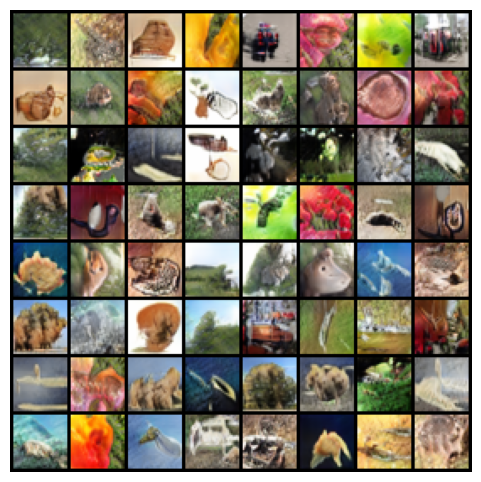

opt_steps 78500 |  loss_D 1.146 |  loss_G 0.863| D(real) +0.40±1.44 |  D(fake) -0.96±1.04 |  margins real>0.34 fake<0.52 |  ||g|| D 14.3 G 12.4 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  64.9 min
opt_steps 79000 |  loss_D 1.157 |  loss_G 0.848| D(real) +1.20±1.48 |  D(fake) -0.61±1.21 |  margins real>0.47 fake<0.38 |  ||g|| D 16.5 G 13.9 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  65.3 min
opt_steps 79500 |  loss_D 1.139 |  loss_G 0.860| D(real) +2.73±3.03 |  D(fake) -0.59±1.04 |  margins real>0.69 fake<0.39 |  ||g|| D 12.9 G 11.9 |  G(x) mean -0.12 std 0.53 range[-1.00,+1.00] |  65.7 min
opt_steps 80000 |  loss_D 1.127 |  loss_G 0.870| D(real) +0.20±2.07 |  D(fake) -1.65±0.70 |  margins real>0.28 fake<0.86 |  ||g|| D 16.4 G 14.6 |  G(x) mean -0.11 std 0.52 range[-1.00,+1.00] |  66.1 min


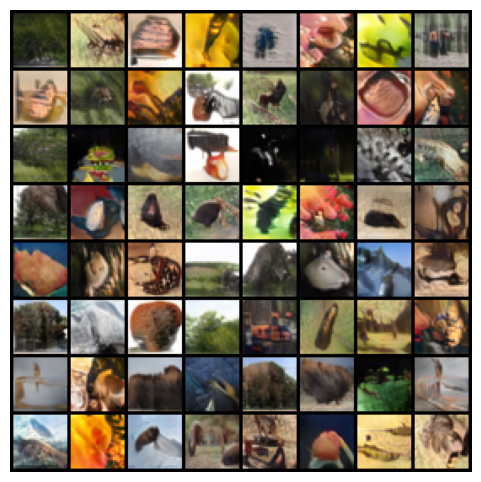

opt_steps 80500 |  loss_D 1.021 |  loss_G 0.963| D(real) +2.10±2.57 |  D(fake) -1.06±1.09 |  margins real>0.59 fake<0.48 |  ||g|| D 15.4 G 14.6 |  G(x) mean -0.12 std 0.48 range[-1.00,+1.00] |  66.5 min
opt_steps 81000 |  loss_D 0.903 |  loss_G 1.088| D(real) +2.25±2.82 |  D(fake) -1.05±1.34 |  margins real>0.66 fake<0.55 |  ||g|| D 15.0 G 16.1 |  G(x) mean -0.09 std 0.53 range[-0.99,+1.00] |  66.9 min
opt_steps 81500 |  loss_D 0.916 |  loss_G 1.080| D(real) +2.33±3.67 |  D(fake) -0.51±1.12 |  margins real>0.58 fake<0.33 |  ||g|| D 19.1 G 14.3 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  67.4 min
opt_steps 82000 |  loss_D 0.935 |  loss_G 1.045| D(real) +1.72±2.74 |  D(fake) -1.36±0.94 |  margins real>0.47 fake<0.67 |  ||g|| D 13.7 G 18.4 |  G(x) mean -0.09 std 0.50 range[-1.00,+1.00] |  67.8 min


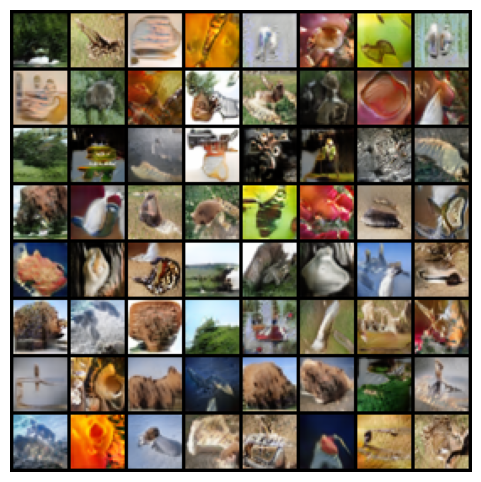

opt_steps 82500 |  loss_D 0.923 |  loss_G 1.067| D(real) +1.32±2.51 |  D(fake) -1.38±1.00 |  margins real>0.41 fake<0.72 |  ||g|| D 14.3 G 18.1 |  G(x) mean -0.09 std 0.52 range[-1.00,+1.00] |  68.2 min
opt_steps 83000 |  loss_D 0.899 |  loss_G 1.086| D(real) +1.50±2.36 |  D(fake) -1.33±0.91 |  margins real>0.53 fake<0.64 |  ||g|| D 15.7 G 18.0 |  G(x) mean -0.12 std 0.50 range[-1.00,+1.00] |  68.6 min
opt_steps 83500 |  loss_D 0.896 |  loss_G 1.087| D(real) +1.91±3.37 |  D(fake) -1.63±0.93 |  margins real>0.58 fake<0.80 |  ||g|| D 12.4 G 17.5 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  69.0 min
opt_steps 84000 |  loss_D 0.894 |  loss_G 1.113| D(real) +2.14±2.85 |  D(fake) -1.19±0.94 |  margins real>0.61 fake<0.61 |  ||g|| D 12.9 G 16.8 |  G(x) mean -0.14 std 0.48 range[-1.00,+1.00] |  69.5 min


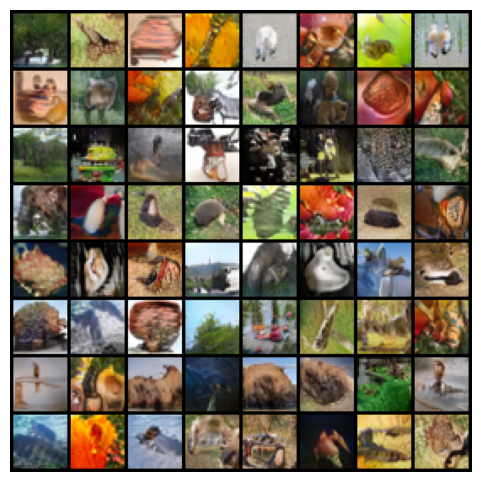

opt_steps 84500 |  loss_D 0.888 |  loss_G 1.117| D(real) +1.80±2.68 |  D(fake) -1.10±0.97 |  margins real>0.53 fake<0.64 |  ||g|| D 12.1 G 16.7 |  G(x) mean -0.11 std 0.53 range[-1.00,+1.00] |  69.9 min
opt_steps 85000 |  loss_D 0.892 |  loss_G 1.103| D(real) +3.10±2.97 |  D(fake) -1.01±1.06 |  margins real>0.80 fake<0.55 |  ||g|| D 13.7 G 15.8 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  70.3 min
opt_steps 85500 |  loss_D 0.875 |  loss_G 1.130| D(real) +1.70±3.26 |  D(fake) -1.55±1.03 |  margins real>0.52 fake<0.70 |  ||g|| D 12.0 G 16.2 |  G(x) mean -0.09 std 0.50 range[-1.00,+1.00] |  70.7 min
opt_steps 86000 |  loss_D 0.867 |  loss_G 1.156| D(real) +1.37±2.89 |  D(fake) -1.46±0.97 |  margins real>0.42 fake<0.70 |  ||g|| D 14.5 G 17.6 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  71.1 min


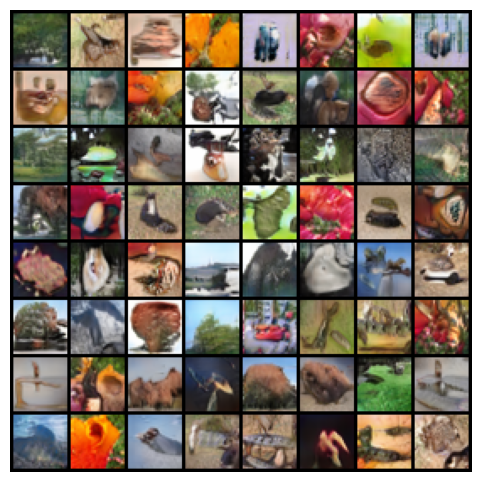

opt_steps 86500 |  loss_D 0.878 |  loss_G 1.149| D(real) +2.40±3.19 |  D(fake) -1.62±1.09 |  margins real>0.62 fake<0.73 |  ||g|| D 13.5 G 16.6 |  G(x) mean -0.13 std 0.52 range[-1.00,+1.00] |  71.6 min
opt_steps 87000 |  loss_D 0.875 |  loss_G 1.159| D(real) +1.84±2.40 |  D(fake) -1.22±0.93 |  margins real>0.62 fake<0.55 |  ||g|| D 16.6 G 17.7 |  G(x) mean -0.12 std 0.50 range[-1.00,+1.00] |  72.0 min
opt_steps 87500 |  loss_D 0.863 |  loss_G 1.165| D(real) +2.99±3.71 |  D(fake) -0.84±0.94 |  margins real>0.64 fake<0.48 |  ||g|| D 14.6 G 19.7 |  G(x) mean -0.12 std 0.46 range[-1.00,+1.00] |  72.4 min
opt_steps 88000 |  loss_D 0.857 |  loss_G 1.142| D(real) +1.40±2.21 |  D(fake) -1.67±1.02 |  margins real>0.45 fake<0.75 |  ||g|| D 14.8 G 18.6 |  G(x) mean -0.12 std 0.52 range[-1.00,+1.00] |  72.8 min


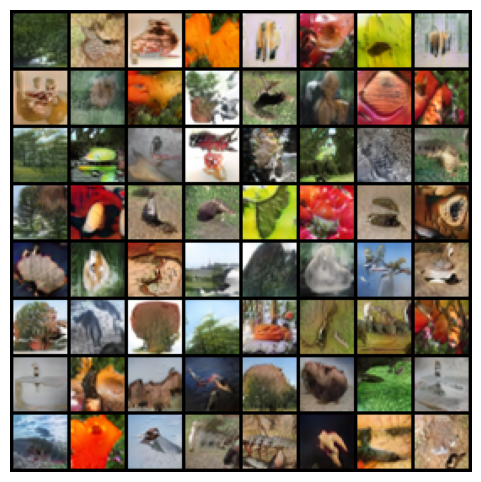

opt_steps 88500 |  loss_D 0.861 |  loss_G 1.141| D(real) +3.03±3.55 |  D(fake) -0.74±1.15 |  margins real>0.69 fake<0.42 |  ||g|| D 15.4 G 15.5 |  G(x) mean -0.12 std 0.48 range[-1.00,+1.00] |  73.2 min
opt_steps 89000 |  loss_D 0.859 |  loss_G 1.162| D(real) +1.31±2.39 |  D(fake) -1.96±1.16 |  margins real>0.45 fake<0.91 |  ||g|| D 20.4 G 18.7 |  G(x) mean -0.13 std 0.49 range[-1.00,+1.00] |  73.6 min
opt_steps 89500 |  loss_D 0.849 |  loss_G 1.180| D(real) +2.29±3.60 |  D(fake) -0.99±1.12 |  margins real>0.59 fake<0.53 |  ||g|| D 14.8 G 18.2 |  G(x) mean -0.14 std 0.51 range[-1.00,+1.00] |  74.1 min
opt_steps 90000 |  loss_D 0.844 |  loss_G 1.172| D(real) +2.66±3.32 |  D(fake) -0.75±1.27 |  margins real>0.67 fake<0.45 |  ||g|| D 18.1 G 16.8 |  G(x) mean -0.10 std 0.52 range[-1.00,+1.00] |  74.5 min


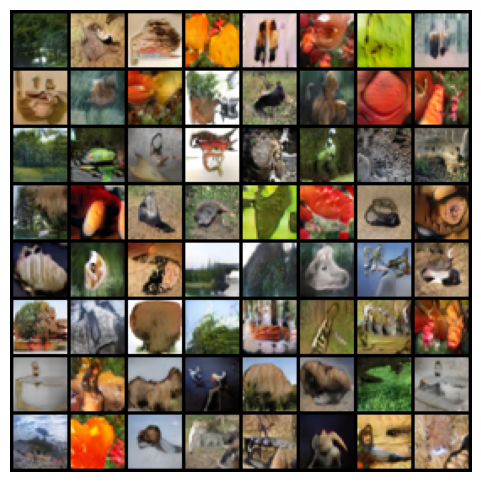

opt_steps 90500 |  loss_D 0.846 |  loss_G 1.163| D(real) +2.20±2.78 |  D(fake) -1.09±0.97 |  margins real>0.61 fake<0.56 |  ||g|| D 15.0 G 21.2 |  G(x) mean -0.14 std 0.47 range[-1.00,+1.00] |  74.9 min
opt_steps 91000 |  loss_D 0.840 |  loss_G 1.176| D(real) +2.98±3.86 |  D(fake) -1.34±1.07 |  margins real>0.64 fake<0.67 |  ||g|| D 17.1 G 17.3 |  G(x) mean -0.15 std 0.50 range[-1.00,+1.00] |  75.3 min
opt_steps 91500 |  loss_D 0.839 |  loss_G 1.184| D(real) +2.32±4.07 |  D(fake) -1.52±0.95 |  margins real>0.44 fake<0.70 |  ||g|| D 18.2 G 19.2 |  G(x) mean -0.13 std 0.51 range[-1.00,+1.00] |  75.7 min
opt_steps 92000 |  loss_D 0.836 |  loss_G 1.199| D(real) +2.94±3.17 |  D(fake) -1.16±1.12 |  margins real>0.67 fake<0.53 |  ||g|| D 14.8 G 19.2 |  G(x) mean -0.10 std 0.54 range[-1.00,+1.00] |  76.1 min


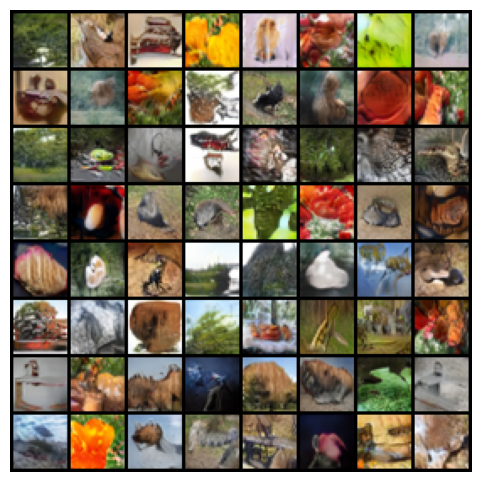

opt_steps 92500 |  loss_D 0.821 |  loss_G 1.202| D(real) +2.04±3.77 |  D(fake) -1.74±0.89 |  margins real>0.44 fake<0.80 |  ||g|| D 16.0 G 17.9 |  G(x) mean -0.14 std 0.50 range[-1.00,+1.00] |  76.6 min
opt_steps 93000 |  loss_D 0.829 |  loss_G 1.183| D(real) +2.24±2.76 |  D(fake) -1.55±1.07 |  margins real>0.64 fake<0.73 |  ||g|| D 17.5 G 20.3 |  G(x) mean -0.12 std 0.48 range[-1.00,+1.00] |  77.0 min
opt_steps 93500 |  loss_D 0.843 |  loss_G 1.180| D(real) +2.83±3.30 |  D(fake) -1.06±0.88 |  margins real>0.73 fake<0.58 |  ||g|| D 12.3 G 18.2 |  G(x) mean -0.13 std 0.49 range[-1.00,+1.00] |  77.4 min
opt_steps 94000 |  loss_D 0.843 |  loss_G 1.176| D(real) +3.04±3.29 |  D(fake) -1.49±1.12 |  margins real>0.72 fake<0.66 |  ||g|| D 13.5 G 20.1 |  G(x) mean -0.11 std 0.44 range[-1.00,+1.00] |  77.8 min


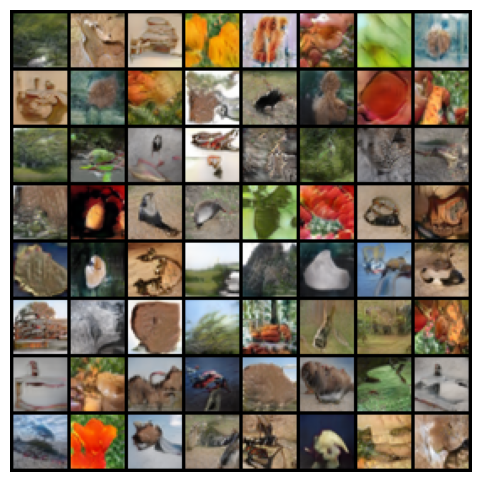

opt_steps 94500 |  loss_D 0.838 |  loss_G 1.164| D(real) +2.44±2.85 |  D(fake) -0.96±1.15 |  margins real>0.62 fake<0.50 |  ||g|| D 19.9 G 17.9 |  G(x) mean -0.08 std 0.50 range[-1.00,+1.00] |  78.2 min
opt_steps 95000 |  loss_D 0.832 |  loss_G 1.184| D(real) +3.88±4.30 |  D(fake) -1.25±1.09 |  margins real>0.80 fake<0.62 |  ||g|| D 14.0 G 20.4 |  G(x) mean -0.11 std 0.45 range[-1.00,+1.00] |  78.6 min
opt_steps 95500 |  loss_D 0.819 |  loss_G 1.204| D(real) +2.50±4.45 |  D(fake) -1.58±0.99 |  margins real>0.55 fake<0.73 |  ||g|| D 12.6 G 20.7 |  G(x) mean -0.08 std 0.52 range[-1.00,+1.00] |  79.1 min
opt_steps 96000 |  loss_D 0.816 |  loss_G 1.198| D(real) +4.58±6.07 |  D(fake) -0.82±1.28 |  margins real>0.70 fake<0.42 |  ||g|| D 20.0 G 15.5 |  G(x) mean -0.13 std 0.49 range[-1.00,+1.00] |  79.5 min


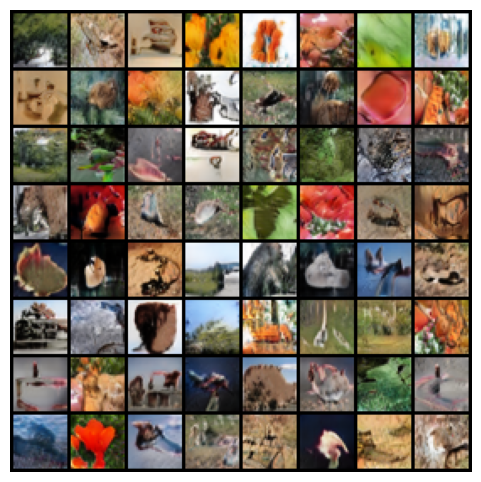

opt_steps 96500 |  loss_D 0.816 |  loss_G 1.201| D(real) +3.31±3.58 |  D(fake) -0.83±1.29 |  margins real>0.69 fake<0.53 |  ||g|| D 17.0 G 18.8 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  79.9 min
opt_steps 97000 |  loss_D 0.813 |  loss_G 1.190| D(real) +2.83±3.10 |  D(fake) -0.85±1.24 |  margins real>0.62 fake<0.50 |  ||g|| D 17.7 G 18.2 |  G(x) mean -0.10 std 0.51 range[-1.00,+1.00] |  80.3 min
opt_steps 97500 |  loss_D 0.811 |  loss_G 1.183| D(real) +2.09±7.27 |  D(fake) -1.69±0.95 |  margins real>0.44 fake<0.70 |  ||g|| D 18.0 G 21.0 |  G(x) mean -0.09 std 0.53 range[-1.00,+1.00] |  80.7 min
opt_steps 98000 |  loss_D 0.812 |  loss_G 1.201| D(real) +3.10±5.11 |  D(fake) -1.01±0.94 |  margins real>0.56 fake<0.53 |  ||g|| D 18.0 G 19.8 |  G(x) mean -0.11 std 0.51 range[-1.00,+1.00] |  81.2 min


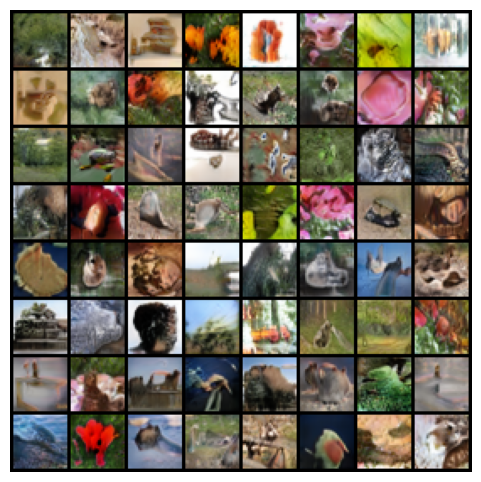

opt_steps 98500 |  loss_D 0.815 |  loss_G 1.226| D(real) +2.05±3.09 |  D(fake) -1.65±0.92 |  margins real>0.50 fake<0.84 |  ||g|| D 18.2 G 23.2 |  G(x) mean -0.12 std 0.50 range[-1.00,+1.00] |  81.6 min
opt_steps 99000 |  loss_D 0.824 |  loss_G 1.215| D(real) +2.77±2.99 |  D(fake) -1.00±0.95 |  margins real>0.73 fake<0.52 |  ||g|| D 16.8 G 17.9 |  G(x) mean -0.08 std 0.55 range[-1.00,+1.00] |  82.0 min
opt_steps 99500 |  loss_D 0.829 |  loss_G 1.197| D(real) +1.43±2.89 |  D(fake) -1.55±0.83 |  margins real>0.39 fake<0.75 |  ||g|| D 17.4 G 19.0 |  G(x) mean -0.12 std 0.53 range[-1.00,+1.00] |  82.4 min
opt_steps 100000 |  loss_D 0.817 |  loss_G 1.215| D(real) +1.66±2.81 |  D(fake) -1.60±0.96 |  margins real>0.45 fake<0.73 |  ||g|| D 17.4 G 21.7 |  G(x) mean -0.16 std 0.49 range[-1.00,+1.00] |  82.8 min


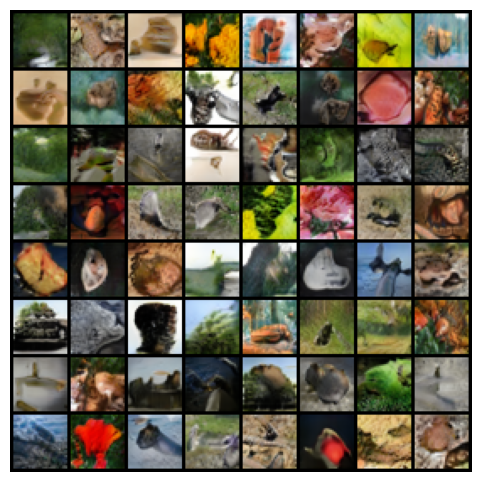

In [16]:
# Hinge Loss Function
def d_hinge_loss(d_real, d_fake):
    loss_real = F.relu(1.0 - d_real).mean()
    loss_fake = F.relu(1.0 + d_fake).mean()
    return loss_real + loss_fake

def g_hinge_loss(d_fake):
    return (-d_fake).mean()

opt_steps = 0
log_every = 500
sample_every = 2000

lossD_hist, lossG_hist = [], []

printed_range = False

G.train(); D.train()

# making this 100k because my email to Chris.
# every 1 discriminator+generator step are considered 1 overall step
# i am incrementing the steps as +1 for each model so just doubled the cap from 50k to 100k
# because then it is actually doing 50k optimisation steps!
while opt_steps < 100000:
    for i in range(1000):
        if opt_steps >= 100000:
            break

        x, _ = next(train_iterator)
        x = x.to(device)
        x = x * 2 - 1   # [0,1] -> [-1,1]
        
        if not printed_range:
            print("x range:", x.min().item(), x.max().item())
            printed_range = True
        
        bsz = x.size(0)
        

        # 1) Train Discriminator
        z = torch.randn(bsz, 128, device=device)
        with torch.no_grad():
            x_fake = G(z)

        p_aug, t_aug = get_aug_params(opt_steps)

        
        x_in      = diff_augment(x,      p=p_aug, translate=t_aug)
        x_fake_in = diff_augment(x_fake, p=p_aug, translate=t_aug)

        d_real = D(x_in)
        d_fake = D(x_fake_in)
        
        loss_D = d_hinge_loss(d_real, d_fake)
        opt_D.zero_grad(set_to_none=True)
        
        # For data analysis
        # logits stats (what D "believes")
        dreal_mean, dreal_std, dreal_min, dreal_max = tensor_stats(d_real)
        dfake_mean, dfake_std, dfake_min, dfake_max = tensor_stats(d_fake)
        # hinge margin satisfaction (super informative for hinge loss)
        real_margin_frac = (d_real > 1.0).float().mean().item()   # fraction of real beyond margin
        fake_margin_frac = (d_fake < -1.0).float().mean().item()  # fraction of fake beyond margin
        
        loss_D.backward()
        
        d_gn = grad_norm(D) # For data analysis
        
        opt_D.step()
        opt_steps += 1
        lossD_hist.append(loss_D.item())
        
        if opt_steps >= 100000:
            break
        
        # 2) Train Generator
        z = torch.randn(bsz, 128, device=device)
        x_fake = G(z)
        p_aug, t_aug = get_aug_params(opt_steps)
        d_fake_for_g = D(diff_augment(x_fake, p=p_aug, translate=t_aug))
        
        # These 4 lines for data analysis
        xf_mean = x_fake.detach().mean().item()
        xf_std  = x_fake.detach().std(unbiased=False).item()
        xf_min  = x_fake.detach().min().item()
        xf_max  = x_fake.detach().max().item()

        loss_G = g_hinge_loss(d_fake_for_g)

        opt_G.zero_grad(set_to_none=True)
        loss_G.backward()
        
        g_gn = grad_norm(G) # For Data analysis
        
        opt_G.step()
        ema_update(G_ema, G, ema_decay)
        opt_steps += 1
        lossG_hist.append(loss_G.item())
        
        if opt_steps == 80000: #was 40k before i changed it
            for pg in opt_G.param_groups: pg["lr"] *= 0.5
            for pg in opt_D.param_groups: pg["lr"] *= 0.5
        

        # Logging
        if opt_steps % log_every == 0:
            elapsed = time.time() - t0
            
            # store for plots
            metrics["step"].append(opt_steps)
            metrics["loss_D"].append(np.mean(lossD_hist[-log_every:]))
            metrics["loss_G"].append(np.mean(lossG_hist[-log_every:]))

            metrics["Dreal_mean"].append(dreal_mean)
            metrics["Dfake_mean"].append(dfake_mean)
            metrics["Dreal_std"].append(dreal_std)
            metrics["Dfake_std"].append(dfake_std)

            metrics["real_margin_frac"].append(real_margin_frac)
            metrics["fake_margin_frac"].append(fake_margin_frac)

            metrics["gradnorm_D"].append(d_gn)
            metrics["gradnorm_G"].append(g_gn)

            metrics["Gx_mean"].append(xf_mean)
            metrics["Gx_std"].append(xf_std)
            metrics["Gx_min"].append(xf_min)
            metrics["Gx_max"].append(xf_max)
    
            print(f"opt_steps {opt_steps:5d} | ",
                  f"loss_D {np.mean(lossD_hist[-log_every:]):.3f} | ",
                  f"loss_G {np.mean(lossG_hist[-log_every:]):.3f}|",
                  f"D(real) {dreal_mean:+.2f}±{dreal_std:.2f} | ",
                  f"D(fake) {dfake_mean:+.2f}±{dfake_std:.2f} | ",
                  f"margins real>{real_margin_frac:.2f} fake<{fake_margin_frac:.2f} | ",
                  f"||g|| D {d_gn:.1f} G {g_gn:.1f} | ",
                  f"G(x) mean {xf_mean:+.2f} std {xf_std:.2f} range[{xf_min:+.2f},{xf_max:+.2f}] | ",
                  f"{elapsed/60:.1f} min")

        # Sampling
        if opt_steps % sample_every == 0:
            G_ema.eval()
            with torch.no_grad():
                samples = G_ema(z_vis_fixed).cpu()
                samples = ((samples + 1) / 2).clamp(0, 1)
            grid = torchvision.utils.make_grid(samples, nrow=8)
            plt.figure(figsize=(6, 6))
            plt.imshow(grid.permute(1, 2, 0))
            plt.axis("off")
            plt.show()
            G_ema.train()

**Latent interpolations**

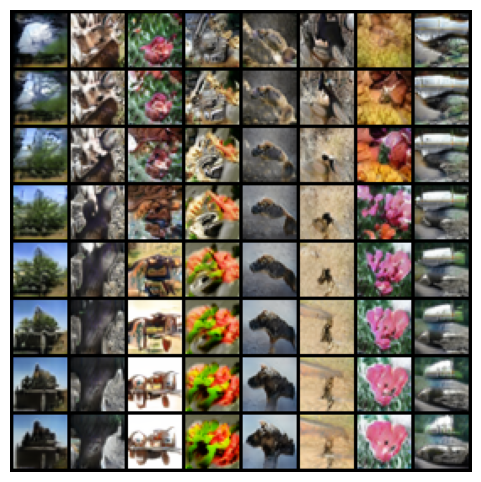

In [17]:
batch_size = 64
z_dim = G.fc.in_features

col_size = int(np.sqrt(batch_size))

z = torch.randn(batch_size, z_dim, device=device)

z0 = z[0:col_size].repeat(col_size, 1)
z1 = z[batch_size-col_size:].repeat(col_size, 1)

t = torch.linspace(0, 1, col_size, device=device).unsqueeze(1)
t = t.repeat(1, col_size).view(batch_size, 1)

lerp_z = (1 - t) * z0 + t * z1

G.eval()
with torch.no_grad():
    lerp_g = G_ema(lerp_z)                         # [-1,1]
    lerp_g = ((lerp_g + 1) / 2).clamp(0, 1)    # [0,1]
G.train()


grid = torchvision.utils.make_grid(lerp_g.cpu(), nrow=col_size)
plt.figure(figsize=(6,6))
plt.imshow(grid.permute(1,2,0))
plt.axis("off")
plt.show()

**FID scores**

Evaluate the FID from 10k of your model samples (do not sample more than this) and compare it against the 10k test images. Calculating FID is somewhat involved, so we use a library for it. It can take a few minutes to evaluate. Lower FID scores are better.

In [18]:
%%capture
!pip install clean-fid
import os
from cleanfid import fid
from torchvision.utils import save_image

In [19]:
import os
import torch
from torchvision.utils import save_image

real_images_dir = 'real_images'
generated_images_dir = 'generated_images'
num_samples = 10_000
batch_size = 64
z_dim = G.fc.in_features  # = 128

def setup_directory(directory):
    if os.path.exists(directory):
        import shutil
        shutil.rmtree(directory)
    os.makedirs(directory)

setup_directory(real_images_dir)
setup_directory(generated_images_dir)

# Generate 10k fake images
G_ema.eval()
num_generated = 0
while num_generated < num_samples:
    z = torch.randn(batch_size, 128, device=device)
    with torch.no_grad():
        samples_batch = G_ema(z).cpu()
        samples_batch = ((samples_batch + 1) / 2).clamp(0, 1)

    for image in samples_batch:
        if num_generated >= num_samples:
            break
        save_image(image, os.path.join(generated_images_dir, f"gen_img_{num_generated}.png"))
        num_generated += 1

G.train()

# Save 10k real test images
num_saved_real = 0

while num_saved_real < num_samples:
    real_batch, _ = next(test_iterator)  # real_batch is [0,1] if ToTensor()
    for image in real_batch:
        if num_saved_real >= num_samples:
            break
        save_image(
            image,
            os.path.join(real_images_dir, f"real_img_{num_saved_real}.png")
        )
        num_saved_real += 1

In [20]:
# compute FID
score = fid.compute_fid(real_images_dir, generated_images_dir, mode="clean")
print(f"FID score: {score}")

compute FID between two folders


/home3/hqcb32/deeplearningcourseworkenv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Found 10000 images in the folder real_images


FID real_images : 100%|██████████| 313/313 [00:39<00:00,  7.90it/s]


Found 10000 images in the folder generated_images


FID generated_images : 100%|██████████| 313/313 [00:38<00:00,  8.05it/s]


FID score: 46.34645017874874


Base Model of ResNetGan with the normalisation with lr=0.0003 for both, FID score: 50.30739274954976

Added Spectral normalisation to the Downsample and discrimantor block but seemed to have made discrimantor too strong since it consistenly keeps getting loss_D=2.000 and loss_G increases extremely slowly. FID score: 88.84023176978047

Spectral normalisation but with G lr=0.0003 and D lr=0.0006 gave FID score: 45.82666195554708 which is an improvement from our base nude model!
Same set up but with G lr=0.0008 and D lr=0.0002 gave FID score: 76.21612970219189

Separately in another notebook I used G lr=0.0003 and D = lr=0.0006 and got FID score: 45.82666195554708 (The parrallel notebook

G lr=0.0004, D lr=0.0001 gave FID score: 84.46107518307309

RESTART:

Nude model but still with EMA gave: FID score: 57.50015438803456
The images are also somewhat readable.

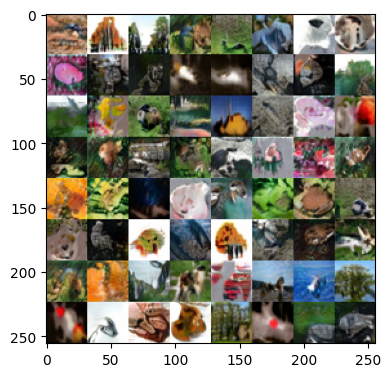

In [21]:
import torch
import matplotlib.pyplot as plt

# ---- settings ----
GRID_SIZE = 8
IMG_SIZE = 32
BATCH_SIZE = GRID_SIZE * GRID_SIZE
z_dim = 128
device = "cuda" if torch.cuda.is_available() else "cpu"

G.eval()

z = torch.randn(BATCH_SIZE, z_dim, device=device)

with torch.no_grad():
    samples = G(z).cpu()

samples = (samples + 1) / 2
samples = samples.clamp(0, 1)

grid = torch.zeros(
    3,
    GRID_SIZE * IMG_SIZE,
    GRID_SIZE * IMG_SIZE
)

idx = 0
for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
        grid[
            :,
            i * IMG_SIZE:(i + 1) * IMG_SIZE,
            j * IMG_SIZE:(j + 1) * IMG_SIZE
        ] = samples[idx]
        idx += 1

# ---- plot like the example ----
plt.figure(figsize=(4, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("on")
plt.xticks(range(0, GRID_SIZE * IMG_SIZE + 1, 50))
plt.yticks(range(0, GRID_SIZE * IMG_SIZE + 1, 50))
plt.tight_layout()
plt.show()

In [22]:
# Computing theKNN pixel space check

import os
import torch
from PIL import Image
from torchvision import transforms

transform = transforms.ToTensor()

def load_images_from_dir(directory):
    images = []
    for fname in os.listdir(directory):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            img = Image.open(os.path.join(directory, fname)).convert("RGB")
            images.append(transform(img))
    return torch.stack(images)

real_images = load_images_from_dir("real_images")         # (N, 3, 32, 32)
gen_images  = load_images_from_dir("generated_images")    # (M, 3, 32, 32)

In [23]:
real_flat = real_images.view(len(real_images), -1)
gen_flat  = gen_images.view(len(gen_images), -1)

# L2 distance between each generated and all real images
distances = torch.cdist(gen_flat, real_flat, p=2)
nn_dist, nn_idx = distances.min(dim=1)

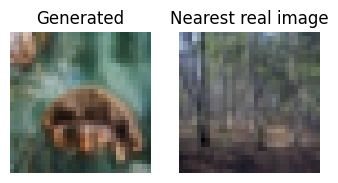

In [24]:
# index of generated image to inspect
i = 0 

fig, axes = plt.subplots(1, 2, figsize=(4, 2))

axes[0].imshow(gen_images[i].permute(1, 2, 0))
axes[0].set_title("Generated")
axes[0].axis("off")

axes[1].imshow(real_images[nn_idx[i]].permute(1, 2, 0))
axes[1].set_title("Nearest real image")
axes[1].axis("off")

plt.show()

In [25]:
print(f"Mean NN distance: {nn_dist.mean():.3f}")
print(f"Std NN distance:  {nn_dist.std():.3f}")

Mean NN distance: 9.467
Std NN distance:  1.949
